
## T1 : Problem Definition and Dataset Preparation


In [1]:
import sys
import numpy as np
import pandas as pd
import sklearn
import torch

print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)


Python executable: c:\Users\MSii\Desktop\ANN CW\.venv\Scripts\python.exe
Python version: 3.13.5
NumPy: 2.5.4
Pandas: 2.3.3
Scikit-learn: 1.9.1
PyTorch: 2.14.1+cpu


In [2]:
from pathlib import Path

DATA_DIR = Path("data")

required_files = [
    "adult.data",
    "adult.test",
    "adult.names"
]

for filename in required_files:
    file_path = DATA_DIR / filename

    print(
        filename,
        "FOUND" if file_path.is_file() else "NOT FOUND"
    )


adult.data FOUND
adult.test FOUND
adult.names FOUND


In [3]:

columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education_num",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
    "native_country",
    "income"
]

train_df = pd.read_csv(
    DATA_DIR / "adult.data",
    names=columns,
    skipinitialspace=True,
    na_values="?"
)

test_df = pd.read_csv(
    DATA_DIR / "adult.test",
    names=columns,
    skiprows=1,
    skipinitialspace=True,
    na_values="?"
)

# Remove the extra period in the official test labels
test_df["income"] = (
    test_df["income"]
    .str.strip()
    .str.rstrip(".")
)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)
print("Total records:", len(train_df) + len(test_df))

display(train_df.head())


Training shape: (32561, 15)
Testing shape: (16281, 15)
Total records: 48842


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [4]:

print("Training target labels:")
print(train_df["income"].value_counts(dropna=False))

print("\nTesting target labels:")
print(test_df["income"].value_counts(dropna=False))

assert set(train_df["income"].dropna().unique()) == {
    "<=50K", ">50K"
}

assert set(test_df["income"].dropna().unique()) == {
    "<=50K", ">50K"
}

print("\nTarget labels verified successfully!")


Training target labels:
income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Testing target labels:
income
<=50K    12435
>50K      3846
Name: count, dtype: int64

Target labels verified successfully!


## T1.2 : Dataset Quality audit

The audit investigates:
- Missing values
- Duplicate records
- Feature data types
- Numerical feature statistics



In [5]:

print("TRAINING DATA — MISSING VALUES")
print("-" * 45)

train_missing = train_df.isnull().sum()

print(train_missing)

print("\nTotal missing values:", train_missing.sum())

print("\nMissing percentages:")
print(
    (train_df.isnull().mean() * 100).round(2)
)


TRAINING DATA — MISSING VALUES
---------------------------------------------
age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64

Total missing values: 4262

Missing percentages:
age               0.00
workclass         5.64
fnlwgt            0.00
education         0.00
education_num     0.00
marital_status    0.00
occupation        5.66
relationship      0.00
race              0.00
sex               0.00
capital_gain      0.00
capital_loss      0.00
hours_per_week    0.00
native_country    1.79
income            0.00
dtype: float64


In [6]:

print("TRAINING DATA — DUPLICATES")
print("-" * 45)

duplicate_count = train_df.duplicated().sum()

duplicate_percentage = (
    duplicate_count / len(train_df)
) * 100

print("Total records:", len(train_df))
print("Duplicate records:", duplicate_count)
print(
    "Duplicate percentage:",
    round(duplicate_percentage, 2),
    "%"
)

print("\nExample duplicate records:")
display(
    train_df[
        train_df.duplicated(keep=False)
    ].head(10)
)


TRAINING DATA — DUPLICATES
---------------------------------------------
Total records: 32561
Duplicate records: 24
Duplicate percentage: 0.07 %

Example duplicate records:


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
2303,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K
3917,19,Private,251579,Some-college,10,Never-married,Other-service,Own-child,White,Male,0,0,14,United-States,<=50K
4325,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico,<=50K
4767,21,Private,250051,Some-college,10,Never-married,Prof-specialty,Own-child,White,Female,0,0,10,United-States,<=50K
4881,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico,<=50K
4940,38,Private,207202,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,48,United-States,>50K
5104,90,Private,52386,Some-college,10,Never-married,Other-service,Not-in-family,Asian-Pac-Islander,Male,0,0,35,United-States,<=50K
5579,27,Private,255582,HS-grad,9,Never-married,Machine-op-inspct,Not-in-family,White,Female,0,0,40,United-States,<=50K
5805,20,Private,107658,Some-college,10,Never-married,Tech-support,Not-in-family,White,Female,0,0,10,United-States,<=50K
5842,25,Private,195994,1st-4th,2,Never-married,Priv-house-serv,Not-in-family,White,Female,0,0,40,Guatemala,<=50K


In [7]:

print("DATA TYPES")
print("-" * 45)

print(train_df.dtypes)

print("\nNumerical columns:")
print(
    train_df.select_dtypes(
        include=["int64", "float64"]
    ).columns.tolist()
)

print("\nCategorical columns:")
print(
    train_df.select_dtypes(
        include=["object"]
    ).columns.tolist()
)


DATA TYPES
---------------------------------------------
age                int64
workclass         object
fnlwgt             int64
education         object
education_num      int64
marital_status    object
occupation        object
relationship      object
race              object
sex               object
capital_gain       int64
capital_loss       int64
hours_per_week     int64
native_country    object
income            object
dtype: object

Numerical columns:
['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

Categorical columns:
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'income']


In [8]:

print("NUMERICAL FEATURE STATISTICS")
print("-" * 45)

display(
    train_df.describe().T
)


NUMERICAL FEATURE STATISTICS
---------------------------------------------


,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education_num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital_gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital_loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours_per_week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0



## T1.3 : Exploratory Data Analysis


In [9]:

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

FIGURE_DIR = Path("outputs/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

print("EDA environment ready.")


EDA environment ready.


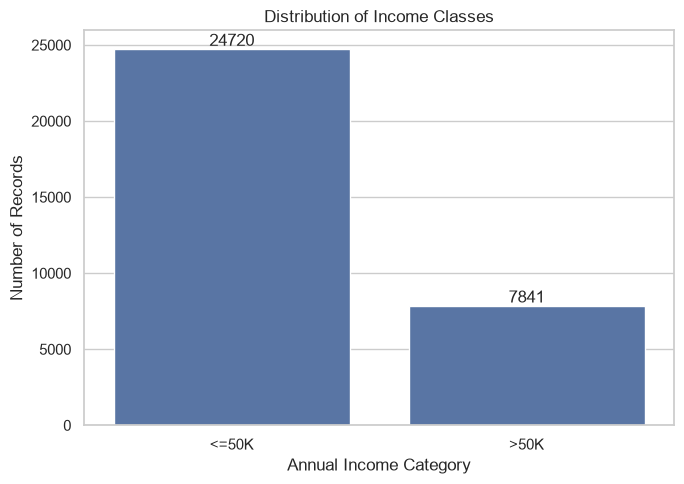

income
<=50K    75.92
>50K     24.08
Name: proportion, dtype: float64


In [10]:

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=train_df,
    x="income",
    order=["<=50K", ">50K"]
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Income Classes")
plt.xlabel("Annual Income Category")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "income_class_distribution.png",
    dpi=300
)
plt.show()

print(
    train_df["income"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


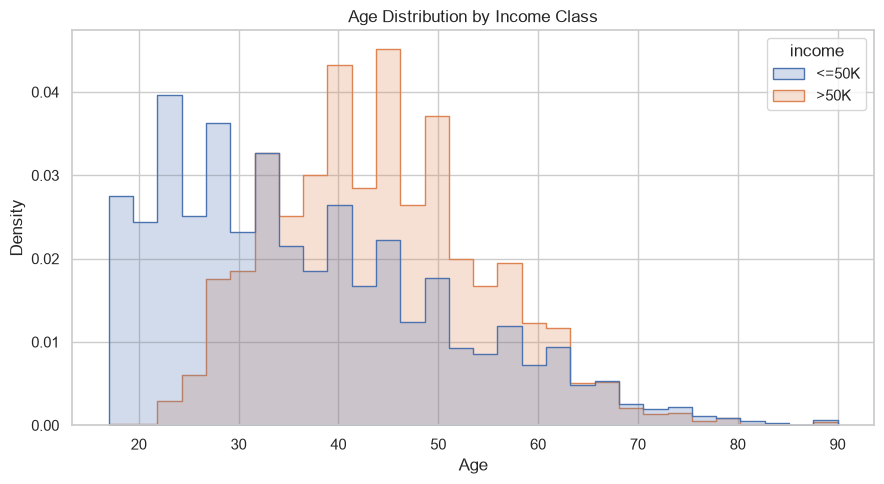

Mean age by income class:
income
<=50K    36.78
>50K     44.25
Name: age, dtype: float64


In [11]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=train_df,
    x="age",
    hue="income",
    bins=30,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Age Distribution by Income Class")
plt.xlabel("Age")
plt.ylabel("Density")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "age_distribution_by_income.png",
    dpi=300
)
plt.show()

print("Mean age by income class:")
print(
    train_df.groupby("income")["age"]
    .mean()
    .round(2)
)


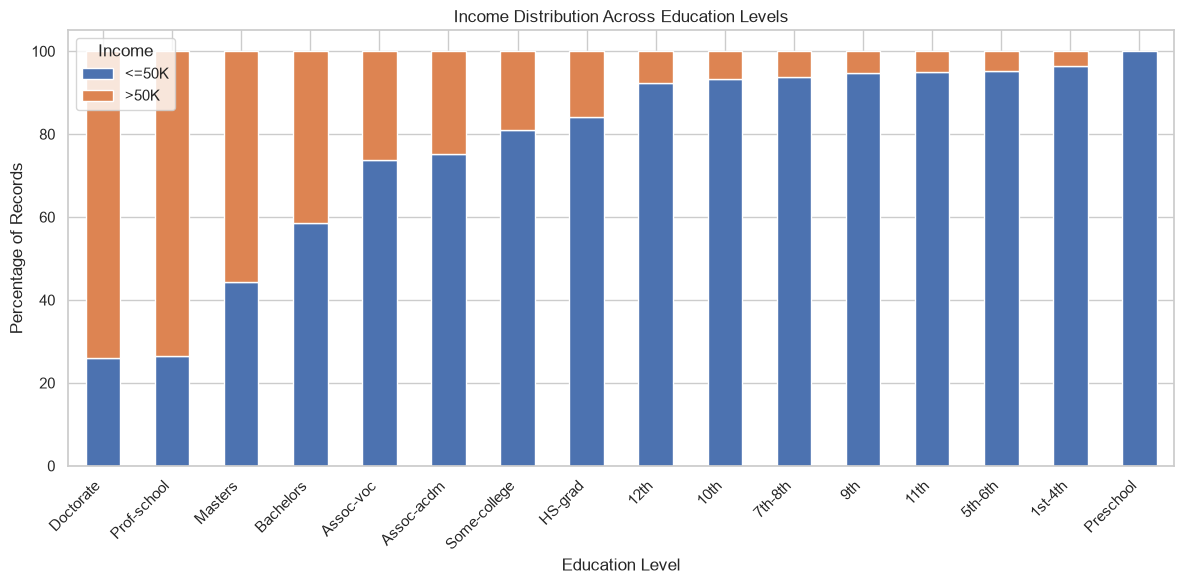

Percentage earning >50K by education:
education
Doctorate       74.09
Prof-school     73.44
Masters         55.66
Bachelors       41.48
Assoc-voc       26.12
Assoc-acdm      24.84
Some-college    19.02
HS-grad         15.95
12th             7.62
10th             6.65
7th-8th          6.19
9th              5.25
11th             5.11
5th-6th          4.80
1st-4th          3.57
Preschool        0.00
Name: >50K, dtype: float64


In [12]:

education_income = pd.crosstab(
    train_df["education"],
    train_df["income"],
    normalize="index"
) * 100

education_income = education_income.sort_values(
    by=">50K",
    ascending=False
)

education_income.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Income Distribution Across Education Levels")
plt.xlabel("Education Level")
plt.ylabel("Percentage of Records")
plt.legend(title="Income")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "education_income_distribution.png",
    dpi=300
)
plt.show()

print("Percentage earning >50K by education:")
print(
    education_income[">50K"].round(2)
)



### EDA Findings and Implications

The income class distribution shows an imbalance, with 75.92%
of development records belonging to the <=50K class and
24.08% belonging to the >50K class. Therefore, accuracy
alone may be misleading, and class-specific evaluation
metrics will be required.

The mean age of individuals earning >50K is 44.25 years,
compared with 36.78 years for individuals earning <=50K.
This indicates an association between age and income.

Education also shows a relationship with income category.
For example, 74.09% of Doctorate holders and 55.66% of
Masters graduates earn >50K, compared with 15.95% of
high-school graduates.

These findings support investigating nonlinear relationships
between census attributes and income using neural networks.
However, the observed associations do not establish causation.



## T1.4 : Data Partitioning

-  official Adult dataset provides separate development and test files.
- Here original test file is reserved for final evaluation.
-  development dataset is split into 80% training and 20% validation using stratified sampling.



In [13]:

import numpy as np
from sklearn.model_selection import train_test_split
from pathlib import Path

SEED = 42

# Separate input features and target
X_full = train_df.drop(columns=["income"])
y_full = (train_df["income"] == ">50K").astype(int)

# Keep official test data separate
X_test = test_df.drop(columns=["income"])
y_test = (test_df["income"] == ">50K").astype(int)

# Original row indices for reproducibility
all_indices = np.arange(len(X_full))

train_idx, val_idx = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=SEED,
    stratify=y_full
)

X_train = X_full.iloc[train_idx].copy()
X_val = X_full.iloc[val_idx].copy()

y_train = y_full.iloc[train_idx].copy()
y_val = y_full.iloc[val_idx].copy()

# Save split indices
SPLIT_DIR = Path("outputs/splits")
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

np.savez(
    SPLIT_DIR / "split_indices.npz",
    train_idx=train_idx,
    val_idx=val_idx
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nValidation class distribution:")
print(y_val.value_counts(normalize=True).round(4))

print("\nSplit indices saved successfully.")


Training: (26048, 14)
Validation: (6513, 14)
Testing: (16281, 14)

Training class distribution:
income
0    0.7592
1    0.2408
Name: proportion, dtype: float64

Validation class distribution:
income
0    0.7593
1    0.2407
Name: proportion, dtype: float64

Split indices saved successfully.


In [14]:

# Check that indices do not overlap
assert len(set(train_idx) & set(val_idx)) == 0

assert len(train_idx) + len(val_idx) == len(X_full)

print("Train/validation indices are disjoint.")

# Check identical input feature combinations across partitions
train_features_unique = X_train.drop_duplicates()
val_features_unique = X_val.drop_duplicates()

overlap = train_features_unique.merge(
    val_features_unique,
    how="inner",
    on=list(X_train.columns)
)

print(
    "Unique feature combinations shared between "
    "training and validation:",
    len(overlap)
)

print("Split integrity checks completed.")


Train/validation indices are disjoint.
Unique feature combinations shared between training and validation: 7
Split integrity checks completed.


In [15]:
 
# Find shared input combinations
shared_features = (
    X_train.drop_duplicates()
    .merge(
        X_val.drop_duplicates(),
        on=list(X_train.columns),
        how="inner"
    )
)

print("Shared unique feature combinations:", len(shared_features))

# Check how many rows are affected
train_overlap = X_train.merge(
    shared_features,
    on=list(X_train.columns),
    how="inner"
)

val_overlap = X_val.merge(
    shared_features,
    on=list(X_val.columns),
    how="inner"
)

print("Affected training rows:", len(train_overlap))
print("Affected validation rows:", len(val_overlap))

display(shared_features.head(10))


Shared unique feature combinations: 7
Affected training rows: 8
Affected validation rows: 7


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country
0,46,Private,173243,HS-grad,9,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States
1,25,Private,308144,Bachelors,13,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,Mexico
2,44,Private,367749,Bachelors,13,Never-married,Prof-specialty,Not-in-family,White,Female,0,0,45,Mexico
3,19,Private,138153,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,10,United-States
4,25,Private,195994,1st-4th,2,Never-married,Priv-house-serv,Not-in-family,White,Female,0,0,40,Guatemala
5,21,Private,250051,Some-college,10,Never-married,Prof-specialty,Own-child,White,Female,0,0,10,United-States
6,49,Private,31267,7th-8th,4,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,United-States



## T1.5 : Leakage-Safe Data Preprocessing



In [16]:

import numpy as np
import pandas as pd

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numeric_features)
print("Number of numerical features:", len(numeric_features))

print("\nCategorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))


Numerical features: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Number of numerical features: 6

Categorical features: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']
Number of categorical features: 8


In [17]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


In [18]:

# Learn preprocessing parameters from training data ONLY
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the already-fitted pipeline to validation data
X_val_processed = preprocessor.transform(X_val)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal validation shape:", X_val.shape)
print("Processed validation shape:", X_val_processed.shape)

print("\nNumber of ANN input features:",
      X_train_processed.shape[1])


Original training shape: (26048, 14)
Processed training shape: (26048, 105)

Original validation shape: (6513, 14)
Processed validation shape: (6513, 105)

Number of ANN input features: 105


In [ ]:

print("Training matrix data type:",
      X_train_processed.dtype)

print("Validation matrix data type:",
      X_val_processed.dtype)

print("\nMissing values in processed training:",
      np.isnan(X_train_processed).sum())

print("Missing values in processed validation:",
      np.isnan(X_val_processed).sum())

print("\nInfinite values in training:",
      np.isinf(X_train_processed).sum())

print("Infinite values in validation:",
      np.isinf(X_val_processed).sum())

assert X_train_processed.shape[0] == len(y_train)
assert X_val_processed.shape[0] == len(y_val)

assert X_train_processed.shape[1] == X_val_processed.shape[1]

assert np.isfinite(X_train_processed).all()
assert np.isfinite(X_val_processed).all()

print("\nAll preprocessing checks passed!")


Training matrix data type: float64
Validation matrix data type: float64

Missing values in processed training: 0
Missing values in processed validation: 0

Infinite values in training: 0
Infinite values in validation: 0

All preprocessing checks passed!


In [20]:

import joblib
from pathlib import Path

MODEL_DIR = Path("outputs/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    preprocessor,
    MODEL_DIR / "preprocessor.joblib"
)

feature_names = preprocessor.get_feature_names_out()

pd.DataFrame({
    "feature_name": feature_names
}).to_csv(
    MODEL_DIR / "processed_feature_names.csv",
    index=False
)

print("Preprocessor saved successfully.")
print("Total processed features:", len(feature_names))

print("\nFirst 15 processed feature names:")
print(feature_names[:15])


Preprocessor saved successfully.
Total processed features: 105

First 15 processed feature names:
['numeric__age' 'numeric__fnlwgt' 'numeric__education_num'
 'numeric__capital_gain' 'numeric__capital_loss' 'numeric__hours_per_week'
 'categorical__workclass_Federal-gov' 'categorical__workclass_Local-gov'
 'categorical__workclass_Never-worked' 'categorical__workclass_Private'
 'categorical__workclass_Self-emp-inc'
 'categorical__workclass_Self-emp-not-inc'
 'categorical__workclass_State-gov' 'categorical__workclass_Without-pay'
 'categorical__education_10th']



# T2 : NumPy Multilayer Perceptron from Scratch

## T2.1 : Network Architecture and Forward Propagation

A fully connected neural network with one hidden layer is
implemented using NumPy.

Architecture:
- Input layer: 105 neurons
- Hidden layer: 16 neurons with ReLU activation
- Output layer: 1 neuron with Sigmoid activation

The hidden layer learns nonlinear relationships between the input features and the target income class.

The output layer produces a probability for the positive class (>50K).

Weights are initialized using He initialization for the ReLU hidden layer. Biases are initialized to zero.


In [21]:

import numpy as np

# Network architecture
input_size = X_train_processed.shape[1]
hidden_size = 16
output_size = 1

# Reproducible random initialization
rng = np.random.default_rng(42)

# Input -> Hidden weights
W1 = rng.standard_normal(
    (input_size, hidden_size)
) * np.sqrt(2.0 / input_size)

b1 = np.zeros((1, hidden_size))

# Hidden -> Output weights
W2 = rng.standard_normal(
    (hidden_size, output_size)
) * np.sqrt(1.0 / hidden_size)

b2 = np.zeros((1, output_size))

print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

total_parameters = (
    W1.size + b1.size + W2.size + b2.size
)

print("\nTotal trainable parameters:", total_parameters)


W1 shape: (105, 16)
b1 shape: (1, 16)
W2 shape: (16, 1)
b2 shape: (1, 1)

Total trainable parameters: 1713


In [22]:

def relu(z):
    return np.maximum(0, z)


def sigmoid(z):
    # Numerically stable sigmoid
    positive = z >= 0
    negative = ~positive

    result = np.empty_like(z, dtype=np.float64)

    result[positive] = 1.0 / (
        1.0 + np.exp(-z[positive])
    )

    exp_z = np.exp(z[negative])
    result[negative] = exp_z / (1.0 + exp_z)

    return result


print("ReLU test:", relu(np.array([-2.0, 0.0, 3.0])))
print("Sigmoid test:", sigmoid(np.array([0.0])))


ReLU test: [0. 0. 3.]
Sigmoid test: [0.5]


In [23]:

def forward_pass(X, W1, b1, W2, b2):

    # Input -> Hidden
    Z1 = X @ W1 + b1

    # Hidden activation
    A1 = relu(Z1)

    # Hidden -> Output
    Z2 = A1 @ W2 + b2

    # Output activation
    A2 = sigmoid(Z2)

    return Z1, A1, Z2, A2


# Test forward propagation using 5 training records
X_sample = X_train_processed[:5]

Z1, A1, Z2, A2 = forward_pass(
    X_sample, W1, b1, W2, b2
)

print("Input shape:", X_sample.shape)
print("Z1 shape:", Z1.shape)
print("A1 shape:", A1.shape)
print("Z2 shape:", Z2.shape)
print("A2 shape:", A2.shape)

print("\nPredicted probabilities:")
print(A2.flatten())

print("\nActual labels:")
print(y_train.iloc[:5].to_numpy())

assert A2.shape == (5, 1)
assert np.isfinite(A2).all()
assert ((A2 >= 0) & (A2 <= 1)).all()

print("\nForward propagation checks passed!")


Input shape: (5, 105)
Z1 shape: (5, 16)
A1 shape: (5, 16)
Z2 shape: (5, 1)
A2 shape: (5, 1)

Predicted probabilities:
[0.48809926 0.47092737 0.45676766 0.5622282  0.5007098 ]

Actual labels:
[1 0 0 0 0]

Forward propagation checks passed!


## T2.2 : Binary Cross-Entropy Loss

In [24]:

def binary_cross_entropy(y_true, y_pred):

    # Convert targets and predictions to column vectors
    y_true = np.asarray(
        y_true, dtype=np.float64
    ).reshape(-1, 1)

    y_pred = np.asarray(
        y_pred, dtype=np.float64
    ).reshape(-1, 1)

    # Avoid log(0), which is undefined
    epsilon = 1e-12

    y_pred = np.clip(
        y_pred,
        epsilon,
        1.0 - epsilon
    )

    # Binary cross-entropy
    loss = -(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

    # Average loss across all records
    return np.mean(loss)


print("BCE function created successfully.")


BCE function created successfully.


In [25]:

# Actual labels for the same 5 training records
y_sample = y_train.iloc[:5].to_numpy()

# Use predictions from your forward pass
sample_loss = binary_cross_entropy(
    y_sample,
    A2
)

print("Actual labels:")
print(y_sample)

print("\nPredicted probabilities:")
print(A2.flatten())

print("\nIndividual record losses:")

for i in range(len(y_sample)):

    individual_loss = binary_cross_entropy(
        [y_sample[i]],
        [A2[i, 0]]
    )

    print(
        f"Record {i+1}: "
        f"Actual={y_sample[i]}, "
        f"Predicted={A2[i, 0]:.4f}, "
        f"Loss={individual_loss:.4f}"
    )

print("\nAverage Binary Cross-Entropy Loss:")
print(round(sample_loss, 6))


Actual labels:
[1 0 0 0 0]

Predicted probabilities:
[0.48809926 0.47092737 0.45676766 0.5622282  0.5007098 ]

Individual record losses:
Record 1: Actual=1, Predicted=0.4881, Loss=0.7172
Record 2: Actual=0, Predicted=0.4709, Loss=0.6366
Record 3: Actual=0, Predicted=0.4568, Loss=0.6102
Record 4: Actual=0, Predicted=0.5622, Loss=0.8261
Record 5: Actual=0, Predicted=0.5007, Loss=0.6946

Average Binary Cross-Entropy Loss:
0.696942


In [26]:

# Case 1: Correct, confident predictions
good_predictions = np.array([
    0.01, 0.99
])

actual_labels = np.array([
    0, 1
])

good_loss = binary_cross_entropy(
    actual_labels,
    good_predictions
)

# Case 2: Incorrect, confident predictions
bad_predictions = np.array([
    0.99, 0.01
])

bad_loss = binary_cross_entropy(
    actual_labels,
    bad_predictions
)

print("Good prediction loss:", round(good_loss, 6))
print("Bad prediction loss:", round(bad_loss, 6))

assert good_loss < bad_loss
assert np.isfinite(sample_loss)

print("\nBCE tests passed!")


Good prediction loss: 0.01005
Bad prediction loss: 4.60517

BCE tests passed!


## T2.3 : Manual Backpropagation

In [27]:

def relu_derivative(z):
    return (z > 0).astype(np.float64)


# Test the derivative
test_values = np.array([-2.0, 0.0, 3.0])

print("Input:", test_values)
print("ReLU derivative:", relu_derivative(test_values))


Input: [-2.  0.  3.]
ReLU derivative: [0. 0. 1.]


In [28]:

def backward_pass(X, y, Z1, A1, A2, W2):

    # Ensure targets have shape (batch_size, 1)
    y = np.asarray(
        y, dtype=np.float64
    ).reshape(-1, 1)

    m = X.shape[0]

    # Step 1: Output layer error
    dZ2 = (A2 - y) / m

    # Step 2: Output layer gradients
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Step 3: Hidden layer error
    dA1 = dZ2 @ W2.T

    dZ1 = dA1 * relu_derivative(Z1)

    # Step 4: Hidden layer gradients
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2


print("Manual backpropagation function created.")


Manual backpropagation function created.


In [29]:

dW1, db1, dW2, db2 = backward_pass(
    X_sample,
    y_sample,
    Z1,
    A1,
    A2,
    W2
)

print("dW1 shape:", dW1.shape)
print("db1 shape:", db1.shape)
print("dW2 shape:", dW2.shape)
print("db2 shape:", db2.shape)

print("\nGradient statistics:")

print("dW1 norm:", np.linalg.norm(dW1))
print("db1 norm:", np.linalg.norm(db1))
print("dW2 norm:", np.linalg.norm(dW2))
print("db2 norm:", np.linalg.norm(db2))

print("\nFirst 5 output-weight gradients:")
print(dW2[:5].flatten())


dW1 shape: (105, 16)
db1 shape: (1, 16)
dW2 shape: (16, 1)
db2 shape: (1, 1)

Gradient statistics:
dW1 norm: 0.5003556718258942
db1 norm: 0.1773968734294878
dW2 norm: 0.2827442876862225
db2 norm: 0.29574645850750264

First 5 output-weight gradients:
[0.00376613 0.07860866 0.         0.06984727 0.11980657]


In [30]:

assert dW1.shape == W1.shape
assert db1.shape == b1.shape

assert dW2.shape == W2.shape
assert db2.shape == b2.shape

assert np.isfinite(dW1).all()
assert np.isfinite(db1).all()

assert np.isfinite(dW2).all()
assert np.isfinite(db2).all()

total_gradients = (
    dW1.size + db1.size + dW2.size + db2.size
)

print("Total gradient values:", total_gradients)

print("\nAll gradient shape and finite-value checks passed!")


Total gradient values: 1713

All gradient shape and finite-value checks passed!



## T2.4 : Numerical Gradient Checking


In [31]:

def calculate_network_loss(X, y, W1, b1, W2, b2):

    Z1, A1, Z2, A2 = forward_pass(
        X, W1, b1, W2, b2
    )

    return binary_cross_entropy(y, A2)


# Test using the same five records
loss_check = calculate_network_loss(
    X_sample,
    y_sample,
    W1,
    b1,
    W2,
    b2
)

print("Network loss:", round(loss_check, 6))

assert np.isclose(loss_check, sample_loss)

print("Network loss function verified!")


Network loss: 0.696942
Network loss function verified!


In [32]:

def numerical_gradient(
    X, y,
    W1, b1, W2, b2,
    parameter_name,
    index,
    epsilon=1e-5
):

    # Copy parameters to avoid changing the originals
    parameters = {
        "W1": W1.copy(),
        "b1": b1.copy(),
        "W2": W2.copy(),
        "b2": b2.copy()
    }

    # Increase the selected parameter
    parameters[parameter_name][index] += epsilon

    loss_plus = calculate_network_loss(
        X, y,
        parameters["W1"],
        parameters["b1"],
        parameters["W2"],
        parameters["b2"]
    )

    # Move the parameter from +epsilon to -epsilon
    parameters[parameter_name][index] -= 2 * epsilon

    loss_minus = calculate_network_loss(
        X, y,
        parameters["W1"],
        parameters["b1"],
        parameters["W2"],
        parameters["b2"]
    )

    # Central finite-difference approximation
    gradient = (
        loss_plus - loss_minus
    ) / (2 * epsilon)

    return gradient


print("Numerical gradient function created.")


Numerical gradient function created.


In [33]:

# Analytical gradients from manual backpropagation
analytical_gradients = {
    "W1": dW1,
    "b1": db1,
    "W2": dW2,
    "b2": db2
}

# Test weights and biases from both layers
test_parameters = [
    ("W1", (0, 0)),
    ("W1", (10, 5)),
    ("W1", (50, 10)),
    ("b1", (0, 0)),
    ("b1", (0, 5)),
    ("W2", (0, 0)),
    ("W2", (5, 0)),
    ("b2", (0, 0))
]

results = []

for name, index in test_parameters:

    analytical = analytical_gradients[name][index]

    numerical = numerical_gradient(
        X_sample,
        y_sample,
        W1, b1, W2, b2,
        name,
        index
    )

    absolute_error = abs(analytical - numerical)

    # Symmetric relative error with a small
    # denominator floor for near-zero gradients
    relative_error = absolute_error / max(
        1e-8,
        abs(analytical) + abs(numerical)
    )

    results.append({
        "Parameter": f"{name}{index}",
        "Analytical": analytical,
        "Numerical": numerical,
        "Absolute Error": absolute_error,
        "Relative Error": relative_error
    })

gradient_results = pd.DataFrame(results)

display(gradient_results)

print(
    "Maximum absolute error:",
    gradient_results["Absolute Error"].max()
)

print(
    "Maximum relative error:",
    gradient_results["Relative Error"].max()
)


,Parameter,Analytical,Numerical,Absolute Error,Relative Error
0,"W1(0, 0)",0.046706,0.046706,1.893347e-12,2.026858e-11
1,"W1(10, 5)",0.000000,0.000000,0.000000e+00,0.000000e+00
2,"W1(50, 10)",0.000000,0.000000,0.000000e+00,0.000000e+00
3,"b1(0, 0)",-0.034273,-0.034273,2.841852e-12,4.145921e-11
4,"b1(0, 5)",0.014263,0.014263,7.172712e-12,2.514409e-10
5,"W2(0, 0)",0.003766,0.003766,2.538351e-12,3.369976e-10
6,"W2(5, 0)",0.079152,0.079152,2.650102e-12,1.674057e-11
7,"b2(0, 0)",0.295746,0.295746,4.322598e-12,7.307945e-12


Maximum absolute error: 7.172712077063714e-12
Maximum relative error: 3.36997628745745e-10


In [34]:

tolerance = 1e-5

max_absolute_error = (
    gradient_results["Absolute Error"].max()
)

max_relative_error = (
    gradient_results["Relative Error"].max()
)

print("Gradient checking tolerance:", tolerance)

print("Maximum absolute error:", max_absolute_error)
print("Maximum relative error:", max_relative_error)

if max_absolute_error < tolerance:
    print("\nGradient checking PASSED!")
else:
    print("\nGradient checking needs investigation.")

assert max_absolute_error < tolerance


Gradient checking tolerance: 1e-05
Maximum absolute error: 7.172712077063714e-12
Maximum relative error: 3.36997628745745e-10

Gradient checking PASSED!


## T2.5 : Gradient Descent and Tiny-Batch Overfitting


In [35]:

def update_parameters(
    W1, b1, W2, b2,
    dW1, db1, dW2, db2,
    learning_rate
):

    W1 = W1 - learning_rate * dW1
    b1 = b1 - learning_rate * db1

    W2 = W2 - learning_rate * dW2
    b2 = b2 - learning_rate * db2

    return W1, b1, W2, b2


print("Gradient descent update function created.")


Gradient descent update function created.


In [36]:

# Select a small, reproducible training subset
tiny_rng = np.random.default_rng(42)

tiny_indices = tiny_rng.choice(
    len(X_train_processed),
    size=16,
    replace=False
)

X_tiny = X_train_processed[tiny_indices].copy()

y_tiny = (
    y_train.iloc[tiny_indices]
    .to_numpy()
    .reshape(-1, 1)
)

print("Tiny batch input shape:", X_tiny.shape)
print("Tiny batch target shape:", y_tiny.shape)

print("\nTarget distribution:")
print(np.unique(y_tiny, return_counts=True))


Tiny batch input shape: (16, 105)
Tiny batch target shape: (16, 1)

Target distribution:
(array([0, 1]), array([12,  4]))


In [37]:

# Fresh initialization for the tiny-batch test
tiny_init_rng = np.random.default_rng(123)

tiny_W1 = tiny_init_rng.standard_normal(
    (input_size, hidden_size)
) * np.sqrt(2.0 / input_size)

tiny_b1 = np.zeros((1, hidden_size))

tiny_W2 = tiny_init_rng.standard_normal(
    (hidden_size, output_size)
) * np.sqrt(1.0 / hidden_size)

tiny_b2 = np.zeros((1, output_size))

initial_tiny_loss = calculate_network_loss(
    X_tiny,
    y_tiny,
    tiny_W1,
    tiny_b1,
    tiny_W2,
    tiny_b2
)

print("Initial tiny-batch loss:", initial_tiny_loss)


Initial tiny-batch loss: 0.6714722237575457


In [38]:

learning_rate = 0.05
max_iterations = 5000
target_loss = 0.01

tiny_loss_history = []

for iteration in range(max_iterations):

    # Step 1: Forward propagation
    Z1_t, A1_t, Z2_t, A2_t = forward_pass(
        X_tiny,
        tiny_W1, tiny_b1,
        tiny_W2, tiny_b2
    )

    # Step 2: Calculate loss
    current_loss = binary_cross_entropy(
        y_tiny,
        A2_t
    )

    tiny_loss_history.append(current_loss)

    # Step 3: Stop if loss is sufficiently small
    if current_loss < target_loss:
        print(
            f"Target loss reached at iteration {iteration}"
        )
        break

    # Step 4: Manual backpropagation
    dW1_t, db1_t, dW2_t, db2_t = backward_pass(
        X_tiny,
        y_tiny,
        Z1_t,
        A1_t,
        A2_t,
        tiny_W2
    )

    # Step 5: Update parameters
    tiny_W1, tiny_b1, tiny_W2, tiny_b2 = update_parameters(
        tiny_W1, tiny_b1, tiny_W2, tiny_b2,
        dW1_t, db1_t, dW2_t, db2_t,
        learning_rate
    )

    if iteration % 500 == 0:
        print(
            f"Iteration {iteration}: Loss = {current_loss:.6f}"
        )

# Recalculate using the final updated parameters
final_tiny_loss = calculate_network_loss(
    X_tiny,
    y_tiny,
    tiny_W1, tiny_b1,
    tiny_W2, tiny_b2
)

print("\nInitial loss:", round(initial_tiny_loss, 6))
print("Final loss:", round(final_tiny_loss, 6))

print(
    "Loss reduction:",
    round(initial_tiny_loss - final_tiny_loss, 6)
)

assert np.isfinite(final_tiny_loss)

if final_tiny_loss < target_loss:
    print("\nTiny-batch overfitting test PASSED!")
else:
    print("\nTarget not reached; inspect the loss curve.")


Iteration 0: Loss = 0.671472


Iteration 500: Loss = 0.011227
Target loss reached at iteration 535

Initial loss: 0.671472
Final loss: 0.009983
Loss reduction: 0.661489

Tiny-batch overfitting test PASSED!


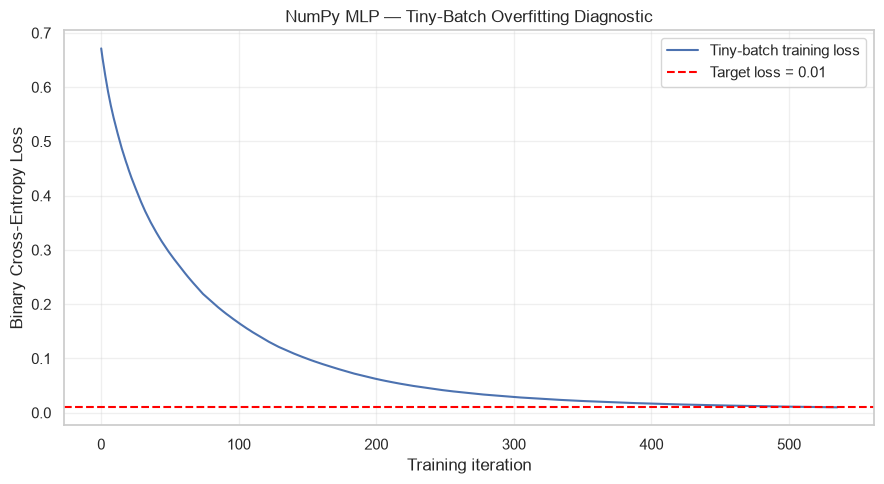

Tiny-batch loss curve saved.


In [39]:

import matplotlib.pyplot as plt
from pathlib import Path

plt.figure(figsize=(9, 5))

plt.plot(
    tiny_loss_history,
    label="Tiny-batch training loss"
)

plt.axhline(
    y=target_loss,
    color="red",
    linestyle="--",
    label="Target loss = 0.01"
)

plt.xlabel("Training iteration")
plt.ylabel("Binary Cross-Entropy Loss")

plt.title(
    "NumPy MLP — Tiny-Batch Overfitting Diagnostic"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

figure_dir = Path("outputs/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "tiny_batch_overfit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Tiny-batch loss curve saved.")


In [40]:

# Predict using trained diagnostic parameters
_, _, _, tiny_probabilities = forward_pass(
    X_tiny,
    tiny_W1, tiny_b1,
    tiny_W2, tiny_b2
)

tiny_predictions = (
    tiny_probabilities >= 0.5
).astype(int)

tiny_accuracy = np.mean(
    tiny_predictions == y_tiny
)

print("Tiny-batch accuracy:", round(tiny_accuracy, 4))

print("\nActual labels:")
print(y_tiny.flatten())

print("\nPredicted labels:")
print(tiny_predictions.flatten())

print("\nFinal tiny-batch loss:")
print(round(final_tiny_loss, 6))


Tiny-batch accuracy: 1.0

Actual labels:
[0 1 0 0 0 0 1 0 0 1 0 0 1 0 0 0]

Predicted labels:
[0 1 0 0 0 0 1 0 0 1 0 0 1 0 0 0]

Final tiny-batch loss:
0.009983



## T2.6 : Full Mini-Batch Training with Validation Monitoring



In [41]:

import numpy as np
from pathlib import Path

# Convert labels into column vectors
y_train_np = y_train.to_numpy().reshape(-1, 1)
y_val_np = y_val.to_numpy().reshape(-1, 1)

# Training configuration
BATCH_SIZE = 64
LEARNING_RATE = 0.01
MAX_EPOCHS = 100
PATIENCE = 10
TRAIN_SEED = 42

print("Training inputs:", X_train_processed.shape)
print("Training labels:", y_train_np.shape)

print("Validation inputs:", X_val_processed.shape)
print("Validation labels:", y_val_np.shape)

print("Mini-batches per epoch:",
      int(np.ceil(len(X_train_processed) / BATCH_SIZE)))


Training inputs: (26048, 105)
Training labels: (26048, 1)
Validation inputs: (6513, 105)
Validation labels: (6513, 1)
Mini-batches per epoch: 407


In [42]:

def evaluate_numpy_mlp(X, y, W1, b1, W2, b2):

    # Forward propagation
    _, _, _, probabilities = forward_pass(
        X, W1, b1, W2, b2
    )

    # Calculate BCE loss
    loss = binary_cross_entropy(
        y, probabilities
    )

    # Convert probabilities to predicted classes
    predictions = (
        probabilities >= 0.5
    ).astype(int)

    # Classification accuracy
    accuracy = np.mean(
        predictions == y
    )

    return loss, accuracy


print("Evaluation function created.")


Evaluation function created.


In [43]:

# Initialize a fresh network for full training
train_rng = np.random.default_rng(TRAIN_SEED)

model_W1 = train_rng.standard_normal(
    (input_size, hidden_size)
) * np.sqrt(2.0 / input_size)

model_b1 = np.zeros((1, hidden_size))

model_W2 = train_rng.standard_normal(
    (hidden_size, output_size)
) * np.sqrt(1.0 / hidden_size)

model_b2 = np.zeros((1, output_size))

# Store learning history
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
best_parameters = None
best_epoch = 0
epochs_without_improvement = 0

n_samples = len(X_train_processed)

for epoch in range(MAX_EPOCHS):

    # Shuffle training records
    indices = train_rng.permutation(n_samples)

    # Mini-batch gradient descent
    for start in range(0, n_samples, BATCH_SIZE):

        batch_indices = indices[
            start:start + BATCH_SIZE
        ]

        X_batch = X_train_processed[batch_indices]
        y_batch = y_train_np[batch_indices]

        # Forward propagation
        Z1, A1, Z2, A2 = forward_pass(
            X_batch,
            model_W1, model_b1,
            model_W2, model_b2
        )

        # Backpropagation
        dW1, db1, dW2, db2 = backward_pass(
            X_batch, y_batch,
            Z1, A1, A2,
            model_W2
        )

        # Update parameters
        model_W1, model_b1, model_W2, model_b2 = (
            update_parameters(
                model_W1, model_b1,
                model_W2, model_b2,
                dW1, db1, dW2, db2,
                LEARNING_RATE
            )
        )

    # Evaluate after each epoch
    train_loss, train_acc = evaluate_numpy_mlp(
        X_train_processed, y_train_np,
        model_W1, model_b1, model_W2, model_b2
    )

    val_loss, val_acc = evaluate_numpy_mlp(
        X_val_processed, y_val_np,
        model_W1, model_b1, model_W2, model_b2
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)

    # Save best parameters based on validation loss
    if val_loss < best_val_loss - 1e-6:

        best_val_loss = val_loss
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        best_parameters = {
            "W1": model_W1.copy(),
            "b1": model_b1.copy(),
            "W2": model_W2.copy(),
            "b2": model_b2.copy()
        }

    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 5 == 0 or epoch == 0:

        print(
            f"Epoch {epoch+1:3d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

    # Early stopping
    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch+1}"
        )
        break

print("\nBest epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 6))


Epoch   1 | Train Loss: 0.4284 | Val Loss: 0.4267 | Train Acc: 0.7847 | Val Acc: 0.7832
Epoch   5 | Train Loss: 0.3402 | Val Loss: 0.3348 | Train Acc: 0.8397 | Val Acc: 0.8431
Epoch  10 | Train Loss: 0.3245 | Val Loss: 0.3187 | Train Acc: 0.8477 | Val Acc: 0.8515
Epoch  15 | Train Loss: 0.3178 | Val Loss: 0.3115 | Train Acc: 0.8512 | Val Acc: 0.8561
Epoch  20 | Train Loss: 0.3144 | Val Loss: 0.3082 | Train Acc: 0.8530 | Val Acc: 0.8569
Epoch  25 | Train Loss: 0.3123 | Val Loss: 0.3061 | Train Acc: 0.8541 | Val Acc: 0.8587
Epoch  30 | Train Loss: 0.3111 | Val Loss: 0.3052 | Train Acc: 0.8550 | Val Acc: 0.8587
Epoch  35 | Train Loss: 0.3104 | Val Loss: 0.3046 | Train Acc: 0.8554 | Val Acc: 0.8604
Epoch  40 | Train Loss: 0.3096 | Val Loss: 0.3040 | Train Acc: 0.8563 | Val Acc: 0.8583
Epoch  45 | Train Loss: 0.3090 | Val Loss: 0.3037 | Train Acc: 0.8557 | Val Acc: 0.8601
Epoch  50 | Train Loss: 0.3085 | Val Loss: 0.3035 | Train Acc: 0.8560 | Val Acc: 0.8594
Epoch  55 | Train Loss: 0.3083 |

In [44]:

# Restore parameters from the best validation epoch
model_W1 = best_parameters["W1"].copy()
model_b1 = best_parameters["b1"].copy()
model_W2 = best_parameters["W2"].copy()
model_b2 = best_parameters["b2"].copy()

# Evaluate the restored model
final_train_loss, final_train_acc = evaluate_numpy_mlp(
    X_train_processed, y_train_np,
    model_W1, model_b1, model_W2, model_b2
)

final_val_loss, final_val_acc = evaluate_numpy_mlp(
    X_val_processed, y_val_np,
    model_W1, model_b1, model_W2, model_b2
)

print("Best epoch:", best_epoch)

print("\nRestored model results:")
print("Training loss:", round(final_train_loss, 6))
print("Validation loss:", round(final_val_loss, 6))
print("Training accuracy:", round(final_train_acc, 4))
print("Validation accuracy:", round(final_val_acc, 4))

assert np.isclose(final_val_loss, best_val_loss)

print("\nBest model restored successfully!")


Best epoch: 100

Restored model results:
Training loss: 0.305529
Validation loss: 0.302398
Training accuracy: 0.8586
Validation accuracy: 0.8607

Best model restored successfully!


In [45]:

MODEL_DIR = Path("outputs/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

np.savez(
    MODEL_DIR / "numpy_mlp_best.npz",
    W1=model_W1,
    b1=model_b1,
    W2=model_W2,
    b2=model_b2,
    best_epoch=best_epoch,
    learning_rate=LEARNING_RATE,
    batch_size=BATCH_SIZE,
    seed=TRAIN_SEED
)

print("Best NumPy MLP saved successfully.")


Best NumPy MLP saved successfully.


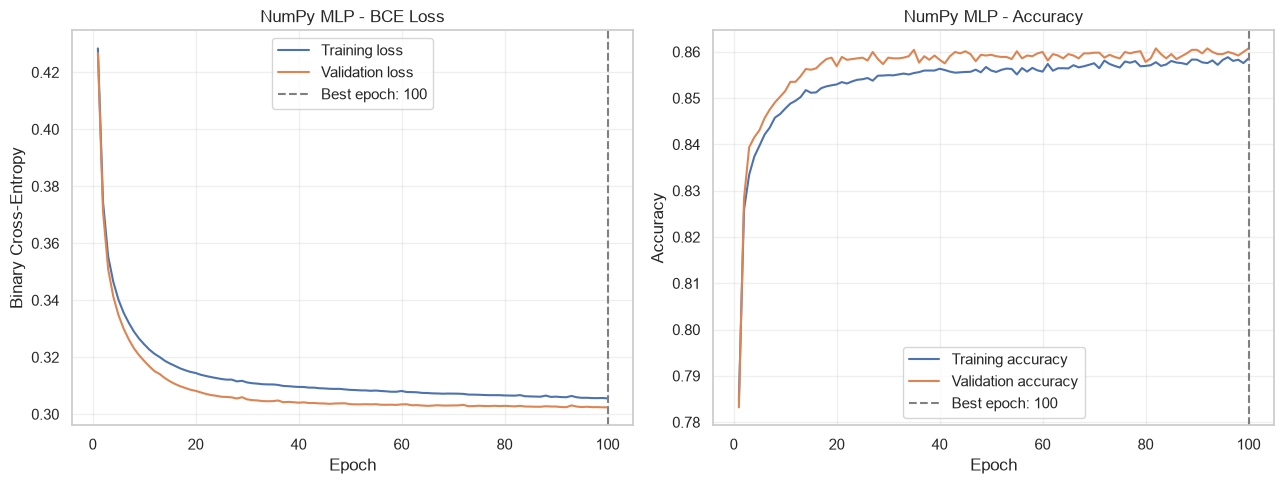

Training curves and history saved.


In [46]:

import matplotlib.pyplot as plt
import pandas as pd

epochs = np.arange(
    1, len(history["train_loss"]) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Loss curve
axes[0].plot(
    epochs,
    history["train_loss"],
    label="Training loss"
)

axes[0].plot(
    epochs,
    history["val_loss"],
    label="Validation loss"
)

axes[0].axvline(
    best_epoch,
    color="gray",
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

axes[0].set_title("NumPy MLP - BCE Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy curve
axes[1].plot(
    epochs,
    history["train_accuracy"],
    label="Training accuracy"
)

axes[1].plot(
    epochs,
    history["val_accuracy"],
    label="Validation accuracy"
)

axes[1].axvline(
    best_epoch,
    color="gray",
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

axes[1].set_title("NumPy MLP - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "outputs/figures/numpy_mlp_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save metrics for reproducibility
pd.DataFrame({
    "epoch": epochs,
    **history
}).to_csv(
    "outputs/models/numpy_mlp_training_history.csv",
    index=False
)

print("Training curves and history saved.")


## T2.7 : Validation Classification Evaluation


In [47]:

# Forward pass using the best trained model
_, _, _, val_probabilities = forward_pass(
    X_val_processed,
    model_W1, model_b1,
    model_W2, model_b2
)

# Convert probabilities to class labels
val_predictions = (
    val_probabilities >= 0.5
).astype(int)

# Convert to 1D arrays for sklearn metrics
y_val_true = y_val_np.flatten()
y_val_pred = val_predictions.flatten()
y_val_prob = val_probabilities.flatten()

print("Actual labels shape:", y_val_true.shape)
print("Predicted labels shape:", y_val_pred.shape)
print("Probabilities shape:", y_val_prob.shape)

print("\nFirst 10 predicted probabilities:")
print(np.round(y_val_prob[:10], 4))

print("\nFirst 10 predicted classes:")
print(y_val_pred[:10])


Actual labels shape: (6513,)
Predicted labels shape: (6513,)
Probabilities shape: (6513,)

First 10 predicted probabilities:
[0.2319 0.0057 0.9661 0.5018 0.0556 0.0077 0.0183 0.5863 0.349  0.0894]

First 10 predicted classes:
[0 0 1 1 0 0 0 1 0 0]


In [48]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(
    y_val_true, y_val_pred
)

precision = precision_score(
    y_val_true, y_val_pred,
    zero_division=0
)

recall = recall_score(
    y_val_true, y_val_pred,
    zero_division=0
)

f1 = f1_score(
    y_val_true, y_val_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_val_true, y_val_prob
)

average_precision = average_precision_score(
    y_val_true, y_val_prob
)

tn, fp, fn, tp = confusion_matrix(
    y_val_true,
    y_val_pred,
    labels=[0, 1]
).ravel()

specificity = tn / (tn + fp)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))
print("Specificity:", round(specificity, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("Average Precision:", round(average_precision, 4))

print("\nConfusion matrix values:")
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

print("\nClassification Report:")
print(classification_report(
    y_val_true,
    y_val_pred,
    target_names=["<=50K", ">50K"],
    zero_division=0
))


Accuracy: 0.8607
Precision: 0.7432
Recall: 0.6441
F1-score: 0.6901
Specificity: 0.9294
ROC-AUC: 0.9164
Average Precision: 0.7939

Confusion matrix values:
TN: 4596
FP: 349
FN: 558
TP: 1010

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      4945
        >50K       0.74      0.64      0.69      1568

    accuracy                           0.86      6513
   macro avg       0.82      0.79      0.80      6513
weighted avg       0.86      0.86      0.86      6513



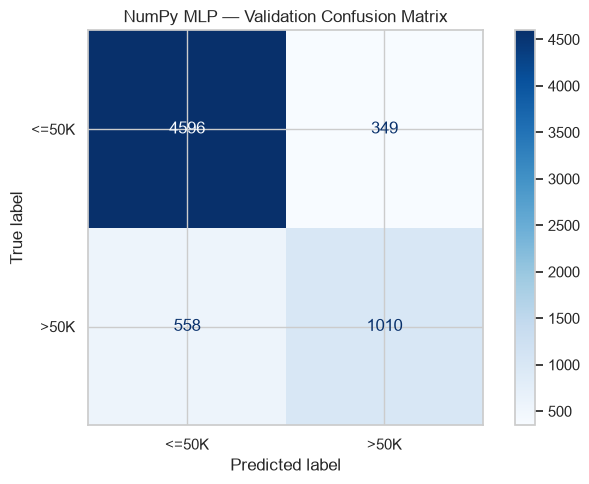

In [49]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_val_true,
    y_val_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["<=50K", ">50K"]
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("NumPy MLP — Validation Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "outputs/figures/numpy_mlp_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [50]:

import json
from pathlib import Path

metrics = {
    "model": "NumPy MLP - 1 Hidden Layer",
    "dataset": "Adult Income",
    "split": "validation",
    "seed": TRAIN_SEED,
    "best_epoch": best_epoch,
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1),
    "specificity": float(specificity),
    "roc_auc": float(roc_auc),
    "average_precision": float(average_precision),
    "true_negative": int(tn),
    "false_positive": int(fp),
    "false_negative": int(fn),
    "true_positive": int(tp)
}

metrics_dir = Path("outputs/metrics")
metrics_dir.mkdir(parents=True, exist_ok=True)

with open(
    metrics_dir / "numpy_mlp_validation_metrics.json",
    "w"
) as file:
    json.dump(metrics, file, indent=4)

print("Validation metrics saved successfully.")


Validation metrics saved successfully.



## T3.1 :  Non-Neural Baseline: Logistic Regression


In [51]:

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=2000,
    solver="lbfgs",
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train_np.ravel()
)

print("Logistic Regression training completed!")

print(
    "Number of iterations:",
    logistic_model.n_iter_
)


Logistic Regression training completed!
Number of iterations: [68]


In [52]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Validation predictions
lr_predictions = logistic_model.predict(
    X_val_processed
)

lr_probabilities = logistic_model.predict_proba(
    X_val_processed
)[:, 1]

# Calculate metrics
lr_metrics = {
    "Accuracy": accuracy_score(
        y_val_true, lr_predictions
    ),
    "Precision": precision_score(
        y_val_true, lr_predictions
    ),
    "Recall": recall_score(
        y_val_true, lr_predictions
    ),
    "F1": f1_score(
        y_val_true, lr_predictions
    ),
    "ROC-AUC": roc_auc_score(
        y_val_true, lr_probabilities
    ),
    "Average Precision": average_precision_score(
        y_val_true, lr_probabilities
    )
}

print("Logistic Regression Validation Results")

for name, value in lr_metrics.items():
    print(f"{name}: {value:.4f}")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val_true,
        lr_predictions
    )
)


Logistic Regression Validation Results
Accuracy: 0.8558
Precision: 0.7406
Recall: 0.6173
F1: 0.6734
ROC-AUC: 0.9078
Average Precision: 0.7732

Confusion Matrix:
[[4606  339]
 [ 600  968]]


In [53]:

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "Average Precision"
    ],
    "NumPy MLP": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        average_precision
    ],
    "Logistic Regression": [
        lr_metrics["Accuracy"],
        lr_metrics["Precision"],
        lr_metrics["Recall"],
        lr_metrics["F1"],
        lr_metrics["ROC-AUC"],
        lr_metrics["Average Precision"]
    ]
})

display(comparison.round(4))


,Metric,NumPy MLP,Logistic Regression
0,Accuracy,0.8607,0.8558
1,Precision,0.7432,0.7406
2,Recall,0.6441,0.6173
3,F1,0.6901,0.6734
4,ROC-AUC,0.9164,0.9078
5,Average Precision,0.7939,0.7732


In [54]:
import json
from pathlib import Path

lr_save_metrics = {
    "model": "Logistic Regression",
    "dataset": "Adult Income",
    "split": "validation",
    "seed": 42,
    "accuracy": float(lr_metrics["Accuracy"]),
    "precision": float(lr_metrics["Precision"]),
    "recall": float(lr_metrics["Recall"]),
    "f1_score": float(lr_metrics["F1"]),
    "roc_auc": float(lr_metrics["ROC-AUC"]),
    "average_precision": float(lr_metrics["Average Precision"]),
    "true_negative": 4606,
    "false_positive": 339,
    "false_negative": 600,
    "true_positive": 968
}

metrics_dir = Path("outputs/metrics")
metrics_dir.mkdir(parents=True, exist_ok=True)

with open(
    metrics_dir / "logistic_regression_validation_metrics.json",
    "w"
) as file:
    json.dump(lr_save_metrics, file, indent=4)

comparison.to_csv(
    metrics_dir / "baseline_model_comparison.csv",
    index=False
)

print("Logistic Regression metrics saved!")
print("Model comparison saved!")

Logistic Regression metrics saved!
Model comparison saved!


In [57]:
import tensorflow as tf
import sys

print("Python version:", sys.version)
print("TensorFlow version:", tf.__version__)

print("\nAvailable devices:")
print(tf.config.list_physical_devices())

print("\nGPU devices:")
print(tf.config.list_physical_devices("GPU"))

# Test TensorFlow calculation
a = tf.constant([[1.0, 2.0], [3.0, 4.0]])
b = tf.constant([[5.0, 6.0], [7.0, 8.0]])

result = tf.matmul(a, b)

print("\nTensorFlow matrix multiplication:")
print(result.numpy())

print("\nTensorFlow installation verified!")

Python version: 3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:15:46) [MSC v.1943 64 bit (AMD64)]
TensorFlow version: 2.21.0

Available devices:
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

GPU devices:
[]

TensorFlow matrix multiplication:
[[19. 22.]
 [43. 50.]]

TensorFlow installation verified!


In [58]:
import tensorflow as tf
import numpy as np
from pathlib import Path

# Set random seeds for reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Convert processed features to float32
X_train_tf = X_train_processed.astype(np.float32)
X_val_tf = X_val_processed.astype(np.float32)

# Convert labels to float32
y_train_tf = np.asarray(y_train_np, dtype=np.float32).reshape(-1, 1)
y_val_tf = np.asarray(y_val_true, dtype=np.float32).reshape(-1, 1)

# Check data shapes
print("Training features:", X_train_tf.shape)
print("Validation features:", X_val_tf.shape)
print("Training labels:", y_train_tf.shape)
print("Validation labels:", y_val_tf.shape)

# Check missing or infinite values
print("\nTraining data contains NaN:", np.isnan(X_train_tf).any())
print("Training data contains infinity:", np.isinf(X_train_tf).any())

print("\nValidation data contains NaN:", np.isnan(X_val_tf).any())
print("Validation data contains infinity:", np.isinf(X_val_tf).any())

Training features: (26048, 105)
Validation features: (6513, 105)
Training labels: (26048, 1)
Validation labels: (6513, 1)

Training data contains NaN: False
Training data contains infinity: False

Validation data contains NaN: False
Validation data contains infinity: False


In [59]:
# Build the Deep MLP architecture

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.regularizers import l2

deep_mlp = Sequential([
    Input(shape=(X_train_tf.shape[1],)),

    # First hidden layer
    Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.0001)
    ),

    # Dropout regularisation
    Dropout(0.30),

    # Second hidden layer
    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.0001)
    ),

    # Binary classification output
    Dense(1, activation="sigmoid")
])

# Compile the model
deep_mlp.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="roc_auc")
    ]
)

# Display architecture
deep_mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         6,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,897 (34.75 KB)

 Trainable params: 8,897 (34.75 KB)

 Non-trainable params: 0 (0.00 B)

In [60]:
# Create output directories
MODEL_DIR = Path("outputs/models")
HISTORY_DIR = Path("outputs/metrics")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
HISTORY_DIR.mkdir(parents=True, exist_ok=True)

# File paths
checkpoint_path = MODEL_DIR / "deep_mlp_best.keras"
history_path = HISTORY_DIR / "deep_mlp_training_history.csv"

# Early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# Save the best model
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_path),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Save training history
csv_logger = tf.keras.callbacks.CSVLogger(
    filename=str(history_path)
)

callbacks = [
    early_stopping,
    model_checkpoint,
    csv_logger
]

print("Training callbacks configured successfully!")
print("Best model:", checkpoint_path)
print("Training history:", history_path)

Training callbacks configured successfully!
Best model: outputs\models\deep_mlp_best.keras
Training history: outputs\metrics\deep_mlp_training_history.csv


In [61]:
# Train the Deep MLP

EPOCHS = 100
BATCH_SIZE = 64

deep_mlp_history = deep_mlp.fit(
    X_train_tf,
    y_train_tf,
    validation_data=(X_val_tf, y_val_tf),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

print("\nDeep MLP training completed!")
print("Best validation loss:", min(deep_mlp_history.history["val_loss"]))
print("Best validation accuracy:", max(deep_mlp_history.history["val_accuracy"]))
print("Epochs completed:", len(deep_mlp_history.history["loss"]))
print("Best model saved:", checkpoint_path.exists())
print("Training history saved:", history_path.exists())

Epoch 1/100
396/407 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8228 - loss: 0.3798 - roc_auc: 0.8694
Epoch 1: val_loss improved from None to 0.32142, saving model to outputs\models\deep_mlp_best.keras

Epoch 1: finished saving model to outputs\models\deep_mlp_best.keras
407/407 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8237 - loss: 0.3788 - roc_auc: 0.8699 - val_accuracy: 0.8554 - val_loss: 0.3214 - val_roc_auc: 0.9112
Epoch 2/100
386/407 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8484 - loss: 0.3337 - roc_auc: 0.9033
Epoch 2: val_loss improved from 0.32142 to 0.31380, saving model to outputs\models\deep_mlp_best.keras

Epoch 2: finished saving model to outputs\models\deep_mlp_best.keras
407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8486 - loss: 0.3334 - roc_auc: 0.9032 - val_accuracy: 0.8598 - val_loss: 0.3138 - val_roc_auc: 0.9150
Epoch 3/100
374/407 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8521 - loss: 0.3257 - roc_auc: 0.9079
Epoch 3: val_loss improved f

Total epochs completed: 30

Best validation loss: 0.3053521513938904
Best validation loss epoch: 20

Best validation accuracy: 0.865192711353302
Best validation accuracy epoch: 19

Best validation ROC-AUC: 0.9190443158149719
Best validation ROC-AUC epoch: 20


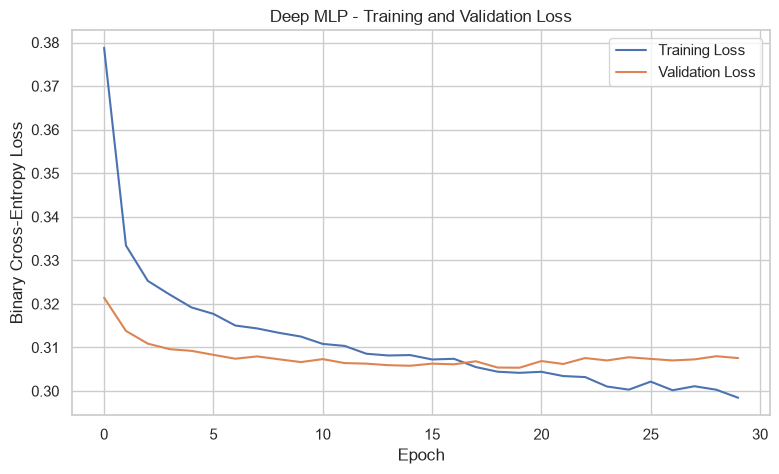

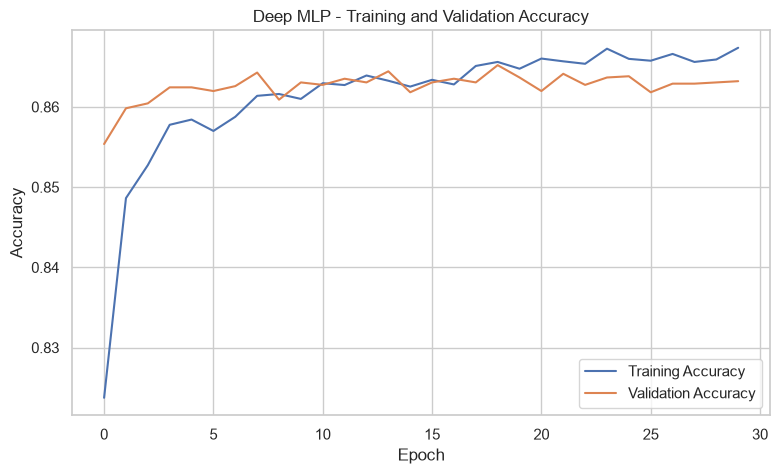


Training history saved successfully!


In [62]:
import matplotlib.pyplot as plt
import numpy as np

# Convert training history into a DataFrame
deep_history_df = pd.DataFrame(deep_mlp_history.history)

# Find best epochs
best_loss_epoch = np.argmin(deep_history_df["val_loss"]) + 1
best_accuracy_epoch = np.argmax(deep_history_df["val_accuracy"]) + 1
best_auc_epoch = np.argmax(deep_history_df["val_roc_auc"]) + 1

print("Total epochs completed:", len(deep_history_df))
print("\nBest validation loss:", deep_history_df["val_loss"].min())
print("Best validation loss epoch:", best_loss_epoch)

print("\nBest validation accuracy:", deep_history_df["val_accuracy"].max())
print("Best validation accuracy epoch:", best_accuracy_epoch)

print("\nBest validation ROC-AUC:", deep_history_df["val_roc_auc"].max())
print("Best validation ROC-AUC epoch:", best_auc_epoch)

# Plot training and validation loss
plt.figure(figsize=(9, 5))
plt.plot(deep_history_df["loss"], label="Training Loss")
plt.plot(deep_history_df["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Deep MLP - Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation accuracy
plt.figure(figsize=(9, 5))
plt.plot(deep_history_df["accuracy"], label="Training Accuracy")
plt.plot(deep_history_df["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Deep MLP - Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Save history
deep_history_df.to_csv(history_path, index=False)
print("\nTraining history saved successfully!")

In [63]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)
import json

# Load the best saved model
best_deep_mlp = tf.keras.models.load_model(checkpoint_path)

# Predict probabilities
y_deep_prob = best_deep_mlp.predict(X_val_tf).ravel()

# Convert probabilities into class predictions
y_deep_pred = (y_deep_prob >= 0.5).astype(int)

# Actual validation labels
y_deep_true = y_val_tf.ravel().astype(int)

# Calculate metrics
deep_metrics = {
    "Accuracy": accuracy_score(y_deep_true, y_deep_pred),
    "Precision": precision_score(y_deep_true, y_deep_pred),
    "Recall": recall_score(y_deep_true, y_deep_pred),
    "F1": f1_score(y_deep_true, y_deep_pred),
    "ROC-AUC": roc_auc_score(y_deep_true, y_deep_prob),
    "Average Precision": average_precision_score(
        y_deep_true, y_deep_prob
    )
}

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_deep_true, y_deep_pred, labels=[0, 1]
).ravel()

deep_metrics["Specificity"] = tn / (tn + fp)

# Display metrics
print("DEEP MLP VALIDATION RESULTS")
print("=" * 40)

for metric, value in deep_metrics.items():
    print(f"{metric}: {value:.4f} ({value * 100:.2f}%)")

print("\nConfusion Matrix:")
print(np.array([[tn, fp], [fn, tp]]))

print("\nClassification Report:")
print(classification_report(
    y_deep_true,
    y_deep_pred,
    target_names=["<=50K", ">50K"]
))

# Save metrics
deep_save_metrics = {
    "model": "Deep MLP",
    "dataset": "Adult Income",
    "split": "validation",
    "seed": SEED,
    "threshold": 0.5,
    **{key.lower().replace(" ", "_"): float(value)
       for key, value in deep_metrics.items()},
    "true_negative": int(tn),
    "false_positive": int(fp),
    "false_negative": int(fn),
    "true_positive": int(tp)
}

deep_metrics_path = Path("outputs/metrics/deep_mlp_validation_metrics.json")

with open(deep_metrics_path, "w") as file:
    json.dump(deep_save_metrics, file, indent=4)

print("\nDeep MLP metrics saved:", deep_metrics_path)

204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 957us/step
DEEP MLP VALIDATION RESULTS
Accuracy: 0.8637 (86.37%)
Precision: 0.7478 (74.78%)
Recall: 0.6543 (65.43%)
F1: 0.6980 (69.80%)
ROC-AUC: 0.9193 (91.93%)
Average Precision: 0.8005 (80.05%)
Specificity: 0.9300 (93.00%)

Confusion Matrix:
[[4599  346]
 [ 542 1026]]

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      4945
        >50K       0.75      0.65      0.70      1568

    accuracy                           0.86      6513
   macro avg       0.82      0.79      0.80      6513
weighted avg       0.86      0.86      0.86      6513


Deep MLP metrics saved: outputs\metrics\deep_mlp_validation_metrics.json


In [64]:
# T3 - Final Comparison of Three Models

import pandas as pd
from sklearn.metrics import confusion_matrix

# Calculate Logistic Regression specificity
lr_tn, lr_fp, lr_fn, lr_tp = confusion_matrix(
    y_val_true,
    lr_predictions,
    labels=[0, 1]
).ravel()

lr_specificity = lr_tn / (lr_tn + lr_fp)

# Create comparison table
comparison_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": lr_metrics["Accuracy"],
        "Precision": lr_metrics["Precision"],
        "Recall": lr_metrics["Recall"],
        "F1-score": lr_metrics["F1"],
        "Specificity": lr_specificity,
        "ROC-AUC": lr_metrics["ROC-AUC"],
        "Average Precision": lr_metrics["Average Precision"]
    },
    {
        "Model": "NumPy MLP (1 Hidden Layer)",
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Specificity": specificity,
        "ROC-AUC": roc_auc,
        "Average Precision": average_precision
    },
    {
        "Model": "Deep MLP (2 Hidden Layers)",
        "Accuracy": deep_metrics["Accuracy"],
        "Precision": deep_metrics["Precision"],
        "Recall": deep_metrics["Recall"],
        "F1-score": deep_metrics["F1"],
        "Specificity": deep_metrics["Specificity"],
        "ROC-AUC": deep_metrics["ROC-AUC"],
        "Average Precision": deep_metrics["Average Precision"]
    }
])

# Display results
print("FINAL THREE-MODEL VALIDATION COMPARISON")
print("=" * 65)

display(
    comparison_results.style.format({
        col: "{:.4f}"
        for col in comparison_results.select_dtypes(
            include="number"
        ).columns
    })
)

# Identify the best model for each metric
print("\nBEST MODEL FOR EACH METRIC")
print("=" * 40)

for metric in comparison_results.columns[1:]:
    best_index = comparison_results[metric].idxmax()

    print(
        f"{metric}: "
        f"{comparison_results.loc[best_index, 'Model']} "
        f"({comparison_results.loc[best_index, metric]:.4f})"
    )

# Save comparison results
metrics_dir = Path("outputs/metrics")
metrics_dir.mkdir(parents=True, exist_ok=True)

comparison_results.to_csv(
    metrics_dir / "three_model_validation_comparison.csv",
    index=False
)

print("\nComparison saved successfully!")
print(
    metrics_dir / "three_model_validation_comparison.csv"
)

FINAL THREE-MODEL VALIDATION COMPARISON


,Model,Accuracy,Precision,Recall,F1-score,Specificity,ROC-AUC,Average Precision
0,Logistic Regression,0.8558,0.7406,0.6173,0.6734,0.9314,0.9078,0.7732
1,NumPy MLP (1 Hidden Layer),0.8607,0.7432,0.6441,0.6901,0.9294,0.9164,0.7939
2,Deep MLP (2 Hidden Layers),0.8637,0.7478,0.6543,0.6980,0.9300,0.9193,0.8005



BEST MODEL FOR EACH METRIC
Accuracy: Deep MLP (2 Hidden Layers) (0.8637)
Precision: Deep MLP (2 Hidden Layers) (0.7478)
Recall: Deep MLP (2 Hidden Layers) (0.6543)
F1-score: Deep MLP (2 Hidden Layers) (0.6980)
Specificity: Logistic Regression (0.9314)
ROC-AUC: Deep MLP (2 Hidden Layers) (0.9193)
Average Precision: Deep MLP (2 Hidden Layers) (0.8005)

Comparison saved successfully!
outputs\metrics\three_model_validation_comparison.csv


# T3 RBF Neural Network

## T3.1 : Import libraries and verify data

In [65]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

tf.keras.utils.set_random_seed(42)

X_rbf_train = np.asarray(X_train_tf, dtype=np.float32)
X_rbf_val = np.asarray(X_val_tf, dtype=np.float32)
y_rbf_train = np.asarray(y_train_tf, dtype=np.float32).reshape(-1, 1)
y_rbf_val = np.asarray(y_val_tf, dtype=np.float32).reshape(-1, 1)

assert X_rbf_train.shape[1] == X_rbf_val.shape[1]
assert X_rbf_train.shape[0] == y_rbf_train.shape[0]
assert X_rbf_val.shape[0] == y_rbf_val.shape[0]
assert np.isfinite(X_rbf_train).all()
assert np.isfinite(X_rbf_val).all()

MODEL_DIR = Path("outputs/models")
METRICS_DIR = Path("outputs/metrics")
FIGURE_DIR = Path("outputs/figures")

for directory in [MODEL_DIR, METRICS_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Training:", X_rbf_train.shape)
print("Validation:", X_rbf_val.shape)
print("Training labels:", y_rbf_train.shape)
print("Validation labels:", y_rbf_val.shape)
print("Data ready for RBF!")


Training: (26048, 105)
Validation: (6513, 105)
Training labels: (26048, 1)
Validation labels: (6513, 1)
Data ready for RBF!


# T3.2 : Select RBF centres

In [66]:

N_CENTERS = 32

kmeans = MiniBatchKMeans(
    n_clusters=N_CENTERS,
    random_state=42,
    batch_size=1024,
    n_init=3
)

kmeans.fit(X_rbf_train)

rbf_centers = kmeans.cluster_centers_.astype(np.float32)

# Estimate a suitable Gaussian width from centre distances
center_distances = np.sqrt(
    np.maximum(
        np.sum(
            (rbf_centers[:, None, :] -
             rbf_centers[None, :, :]) ** 2,
            axis=2
        ),
        0
    )
)

positive_distances = center_distances[
    center_distances > 1e-6
]

sigma = (
    float(np.median(positive_distances))
    if len(positive_distances) else 1.0
)

gamma = 1.0 / (2.0 * sigma ** 2)

print("Number of RBF centres:", len(rbf_centers))
print("Centre shape:", rbf_centers.shape)
print("Initial sigma:", sigma)
print("Initial gamma:", gamma)


Number of RBF centres: 32
Centre shape: (32, 105)
Initial sigma: 3.280142307281494
Initial gamma: 0.04647127978668693


# T3.3 : Build Gaussian RBF layer

In [67]:

@tf.keras.utils.register_keras_serializable(package="AdultIncome")
class GaussianRBFLayer(tf.keras.layers.Layer):

    def __init__(self, centers, gamma=1.0, **kwargs):
        super().__init__(**kwargs)
        self.initial_centers = np.asarray(
            centers, dtype=np.float32
        )
        self.initial_gamma = float(gamma)

    def build(self, input_shape):
        self.centers = self.add_weight(
            name="centers",
            shape=self.initial_centers.shape,
            initializer=tf.keras.initializers.Constant(
                self.initial_centers
            ),
            trainable=True
        )

        self.log_gamma = self.add_weight(
            name="log_gamma",
            shape=(),
            initializer=tf.keras.initializers.Constant(
                np.log(self.initial_gamma)
            ),
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):
        # Squared Euclidean distances
        x_sq = tf.reduce_sum(
            tf.square(inputs), axis=1, keepdims=True
        )

        c_sq = tf.reduce_sum(
            tf.square(self.centers), axis=1
        )

        distances = tf.maximum(
            x_sq - 2.0 * tf.matmul(
                inputs, self.centers, transpose_b=True
            ) + c_sq,
            0.0
        )

        gamma = tf.exp(
            tf.clip_by_value(self.log_gamma, -12.0, 5.0)
        )

        return tf.exp(-gamma * distances)

    def get_config(self):
        config = super().get_config()
        config.update({
            "centers": self.initial_centers.tolist(),
            "gamma": self.initial_gamma
        })
        return config


rbf_model = tf.keras.Sequential([
    tf.keras.Input(shape=(X_rbf_train.shape[1],)),
    GaussianRBFLayer(
        centers=rbf_centers,
        gamma=gamma,
        name="gaussian_rbf"
    ),
    tf.keras.layers.Dense(
        1,
        activation="sigmoid",
        name="output"
    )
])

rbf_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="roc_auc")
    ]
)

rbf_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gaussian_rbf (GaussianRBFLayer) │ (None, 32)             │         3,361 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,394 (13.26 KB)

 Trainable params: 3,394 (13.26 KB)

 Non-trainable params: 0 (0.00 B)

# T3.4 : Train RBF Network

In [68]:

rbf_checkpoint = MODEL_DIR / "rbf_best.keras"

rbf_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(rbf_checkpoint),
        monitor="val_loss",
        save_best_only=True,
        mode="min"
    ),
    tf.keras.callbacks.CSVLogger(
        str(METRICS_DIR / "rbf_training_history.csv")
    )
]

rbf_history = rbf_model.fit(
    X_rbf_train,
    y_rbf_train,
    validation_data=(X_rbf_val, y_rbf_val),
    epochs=100,
    batch_size=64,
    callbacks=rbf_callbacks,
    shuffle=True,
    verbose=1
)

print("RBF training completed!")
print("Epochs:", len(rbf_history.history["loss"]))
print("Best validation loss:",
      min(rbf_history.history["val_loss"]))
print("Checkpoint saved:", rbf_checkpoint.exists())


Epoch 1/100
407/407 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7490 - loss: 0.5047 - roc_auc: 0.7474 - val_accuracy: 0.7619 - val_loss: 0.4464 - val_roc_auc: 0.8595
Epoch 2/100
407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7921 - loss: 0.4212 - roc_auc: 0.8646 - val_accuracy: 0.8154 - val_loss: 0.3973 - val_roc_auc: 0.8746
Epoch 3/100
407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8229 - loss: 0.3871 - roc_auc: 0.8750 - val_accuracy: 0.8343 - val_loss: 0.3739 - val_roc_auc: 0.8809
Epoch 4/100
407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8313 - loss: 0.3700 - roc_auc: 0.8806 - val_accuracy: 0.8405 - val_loss: 0.3609 - val_roc_auc: 0.8856
Epoch 5/100
407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8347 - loss: 0.3600 - roc_auc: 0.8846 - val_accuracy: 0.8435 - val_loss: 0.3525 - val_roc_auc: 0.8894
Epoch 6/100
407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8371 - loss: 0.3532 - roc_auc: 0.8880 - val_accuracy: 0.8454 - val_loss: 0.3465 - val_ro

## Step 5 : Plot training and validation loss

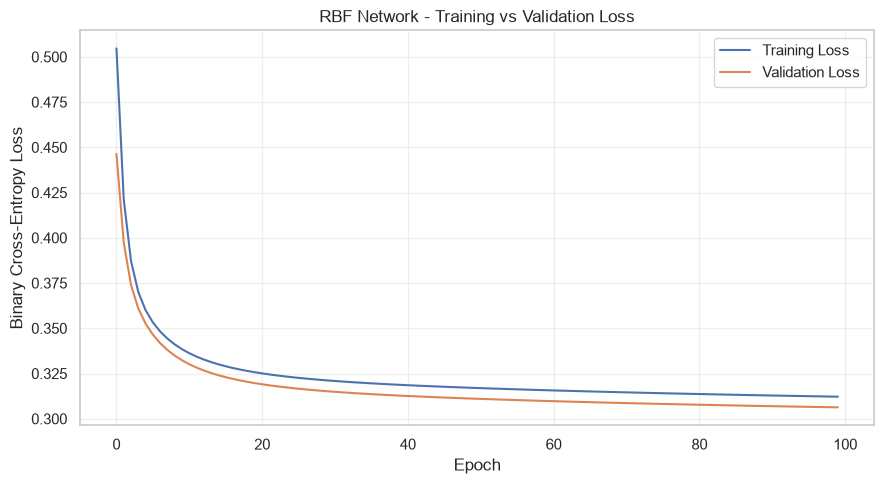

In [69]:

plt.figure(figsize=(9, 5))

plt.plot(
    rbf_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    rbf_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("RBF Network - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "rbf_training_loss.png",
    dpi=300
)

plt.show()


## Step 6 : Evaluate RBF on validation data

In [70]:

best_rbf = tf.keras.models.load_model(
    rbf_checkpoint,
    custom_objects={"GaussianRBFLayer": GaussianRBFLayer}
)

rbf_prob = best_rbf.predict(
    X_rbf_val, verbose=0
).ravel()

rbf_pred = (rbf_prob >= 0.5).astype(int)
rbf_true = y_rbf_val.ravel().astype(int)

rbf_metrics = {
    "Model": "RBF Network",
    "Accuracy": accuracy_score(rbf_true, rbf_pred),
    "Precision": precision_score(
        rbf_true, rbf_pred, zero_division=0
    ),
    "Recall": recall_score(
        rbf_true, rbf_pred, zero_division=0
    ),
    "F1-score": f1_score(
        rbf_true, rbf_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(rbf_true, rbf_prob),
    "Average Precision": average_precision_score(
        rbf_true, rbf_prob
    )
}

rbf_metrics_df = pd.DataFrame([rbf_metrics])

print("RBF VALIDATION RESULTS")
print(rbf_metrics_df.to_string(index=False))

print("\nClassification Report:")
print(classification_report(rbf_true, rbf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(rbf_true, rbf_pred))

rbf_metrics_df.to_csv(
    METRICS_DIR / "rbf_validation_metrics.csv",
    index=False
)

print("\nRBF validation results saved!")


RBF VALIDATION RESULTS
      Model  Accuracy  Precision   Recall  F1-score  ROC-AUC  Average Precision
RBF Network   0.85813   0.752747 0.611607  0.674877 0.914149           0.787291

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.94      0.91      4945
           1       0.75      0.61      0.67      1568

    accuracy                           0.86      6513
   macro avg       0.82      0.77      0.79      6513
weighted avg       0.85      0.86      0.85      6513


Confusion Matrix:
[[4630  315]
 [ 609  959]]

RBF validation results saved!


In [71]:

import pandas as pd
from pathlib import Path

metrics_dir = Path("outputs/metrics")

# Existing validation comparison
existing = pd.read_csv(
    metrics_dir / "three_model_validation_comparison.csv"
)

# New RBF validation results
rbf = pd.read_csv(
    metrics_dir / "rbf_validation_metrics.csv"
)

# T3 framework comparison:
# NumPy MLP belongs to T2, not the two framework architectures.
framework = existing[
    existing["Model"].str.contains(
        "Logistic Regression|Deep MLP",
        case=False,
        regex=True
    )
].copy()

# Keep columns common to both files
common_cols = [
    "Model", "Accuracy", "Precision",
    "Recall", "F1-score", "ROC-AUC",
    "Average Precision"
]

comparison = pd.concat(
    [framework[common_cols], rbf[common_cols]],
    ignore_index=True
)

comparison = comparison.sort_values(
    "F1-score", ascending=False
)

print("T3 FRAMEWORK MODEL VALIDATION COMPARISON")
print("=" * 55)
print(comparison.to_string(index=False))

comparison.to_csv(
    metrics_dir / "framework_model_validation_comparison.csv",
    index=False
)

print("\nBest validation F1 model:")
print(comparison.iloc[0]["Model"])
print("\nComparison saved successfully!")


T3 FRAMEWORK MODEL VALIDATION COMPARISON
                     Model  Accuracy  Precision   Recall  F1-score  ROC-AUC  Average Precision
Deep MLP (2 Hidden Layers)  0.863657   0.747813 0.654337  0.697959 0.919267           0.800454
               RBF Network  0.858130   0.752747 0.611607  0.674877 0.914149           0.787291
       Logistic Regression  0.855827   0.740627 0.617347  0.673391 0.907801           0.773204

Best validation F1 model:
Deep MLP (2 Hidden Layers)

Comparison saved successfully!


# T4.1 : Repeated Evaluation Using Three Random Seeds.

## Step 1 : Verify the existing Deep MLP configuration

In [72]:

import tensorflow as tf
import numpy as np

print("===== EXISTING DEEP MLP =====")

print("Model type:", type(deep_mlp).__name__)
deep_mlp.summary()

print("\nOptimizer:")
print(deep_mlp.optimizer.get_config())

print("\nLoss:")
print(deep_mlp.loss)

print("\nTraining data:")
print("X:", np.shape(X_train_tf))
print("y:", np.shape(y_train_tf))

print("\nValidation data:")
print("X:", np.shape(X_val_tf))
print("y:", np.shape(y_val_tf))

print("\nRBF configuration:")
print("Centres:", N_CENTERS)
print("Gamma:", gamma)


===== EXISTING DEEP MLP =====
Model type: Sequential


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         6,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,693 (104.27 KB)

 Trainable params: 8,897 (34.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 17,796 (69.52 KB)


Optimizer:
{'name': 'adam', 'learning_rate': 0.0010000000474974513, 'weight_decay': None, 'clipnorm': None, 'global_clipnorm': None, 'clipvalue': None, 'use_ema': False, 'ema_momentum': 0.99, 'ema_overwrite_frequency': None, 'loss_scale_factor': None, 'gradient_accumulation_steps': None, 'beta_1': 0.9, 'beta_2': 0.999, 'epsilon': 1e-07, 'amsgrad': False}

Loss:
binary_crossentropy

Training data:
X: (26048, 105)
y: (26048, 1)

Validation data:
X: (6513, 105)
y: (6513, 1)

RBF configuration:
Centres: 32
Gamma: 0.04647127978668693


# T4.1 : Repeated Evaluation with Three Random Seeds

In [74]:

import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

SEEDS = [42, 123, 2026]
OUT = Path("outputs")
(OUT / "models").mkdir(parents=True, exist_ok=True)
(OUT / "metrics").mkdir(parents=True, exist_ok=True)

Xtr = np.asarray(X_train_tf, dtype=np.float32)
Xva = np.asarray(X_val_tf, dtype=np.float32)
ytr = np.asarray(y_train_tf, dtype=np.float32).reshape(-1, 1)
yva = np.asarray(y_val_tf, dtype=np.float32).reshape(-1, 1)
ytrue = yva.ravel().astype(int)

# Preserve the exact original Deep MLP architecture
def build_deep_mlp(seed):
    tf.keras.utils.set_random_seed(seed)
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(Xtr.shape[1],)),
        tf.keras.layers.Dense(
            64, activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(0.0001)
        ),
        tf.keras.layers.Dropout(0.30),
        tf.keras.layers.Dense(
            32, activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(0.0001)
        ),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(0.001),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="roc_auc")]
    )
    return model

# Build RBF with seed-specific KMeans centres
def build_rbf(seed):
    tf.keras.utils.set_random_seed(seed)

    km = MiniBatchKMeans(
        n_clusters=32, random_state=seed,
        batch_size=1024, n_init=3
    )
    km.fit(Xtr)
    centers = km.cluster_centers_.astype(np.float32)

    distances = np.linalg.norm(
        centers[:, None, :] - centers[None, :, :],
        axis=2
    )
    positive = distances[distances > 1e-6]
    sigma = float(np.median(positive)) if len(positive) else 1.0
    gamma_seed = 1.0 / (2.0 * sigma**2)

    model = tf.keras.Sequential([
        tf.keras.Input(shape=(Xtr.shape[1],)),
        GaussianRBFLayer(
            centers=centers, gamma=gamma_seed,
            name="gaussian_rbf"
        ),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(0.001),
        loss="binary_crossentropy",
        metrics=["accuracy", tf.keras.metrics.AUC(name="roc_auc")]
    )
    return model

results = []

for model_name, builder in [
    ("Deep MLP", build_deep_mlp),
    ("RBF Network", build_rbf)
]:
    for seed in SEEDS:
        tf.keras.backend.clear_session()
        print(f"\nTraining {model_name} | Seed {seed}")

        model = builder(seed)
        filename = (
            model_name.lower().replace(" ", "_")
            + f"_seed_{seed}.keras"
        )
        checkpoint = OUT / "models" / filename

        callbacks = [
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=10,
                restore_best_weights=True
            ),
            tf.keras.callbacks.ModelCheckpoint(
                str(checkpoint),
                monitor="val_loss",
                save_best_only=True
            )
        ]

        history = model.fit(
            Xtr, ytr,
            validation_data=(Xva, yva),
            epochs=100,
            batch_size=64,
            callbacks=callbacks,
            shuffle=True,
            verbose=0
        )

        best = tf.keras.models.load_model(
            checkpoint,
            custom_objects={
                "GaussianRBFLayer": GaussianRBFLayer
            }
        )

        prob = best.predict(Xva, verbose=0).ravel()
        pred = (prob >= 0.5).astype(int)

        row = {
            "Model": model_name,
            "Seed": seed,
            "Epochs": len(history.history["loss"]),
            "Parameters": best.count_params(),
            "Accuracy": accuracy_score(ytrue, pred),
            "Precision": precision_score(
                ytrue, pred, zero_division=0
            ),
            "Recall": recall_score(
                ytrue, pred, zero_division=0
            ),
            "F1-score": f1_score(
                ytrue, pred, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(ytrue, prob),
            "Checkpoint": str(checkpoint)
        }
        results.append(row)

        # Save immediately, even if a later run is interrupted
        pd.DataFrame(results).to_csv(
            OUT / "metrics" / "three_seed_results.csv",
            index=False
        )

        print(
            f"Accuracy={row['Accuracy']:.4f} | "
            f"F1={row['F1-score']:.4f} | "
            f"AUC={row['ROC-AUC']:.4f}"
        )

results_df = pd.DataFrame(results)

summary = results_df.groupby("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
].agg(["mean", "std"])

summary.to_csv(
    OUT / "metrics" / "three_seed_mean_std.csv"
)

print("\n===== INDIVIDUAL RESULTS =====")
print(results_df.drop(columns=["Checkpoint"]).to_string(index=False))

print("\n===== MEAN AND STANDARD DEVIATION =====")
print(summary.round(4))

print("\nT4.1 completed!")



Training Deep MLP | Seed 42
Accuracy=0.8637 | F1=0.6980 | AUC=0.9193

Training Deep MLP | Seed 123
Accuracy=0.8604 | F1=0.6862 | AUC=0.9183

Training Deep MLP | Seed 2026
Accuracy=0.8618 | F1=0.6968 | AUC=0.9190

Training RBF Network | Seed 42
Accuracy=0.8581 | F1=0.6749 | AUC=0.9141

Training RBF Network | Seed 123
Accuracy=0.8586 | F1=0.6830 | AUC=0.9124

Training RBF Network | Seed 2026
Accuracy=0.8586 | F1=0.6834 | AUC=0.9150

===== INDIVIDUAL RESULTS =====
      Model  Seed  Epochs  Parameters  Accuracy  Precision   Recall  F1-score  ROC-AUC
   Deep MLP    42      30        8897  0.863657   0.747813 0.654337  0.697959 0.919267
   Deep MLP   123      26        8897  0.860433   0.747931 0.633929  0.686227 0.918255
   Deep MLP  2026      35        8897  0.861815   0.738571 0.659439  0.696765 0.918957
RBF Network    42     100        3394  0.858130   0.752747 0.611607  0.674877 0.914149
RBF Network   123     100        3394  0.858591   0.741960 0.632653  0.682960 0.912431
RBF Network

# T4.2 : Ablation Study: Effect of Dropout

In [75]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

SEEDS = [42, 123, 2026]

METRICS_DIR = Path("outputs/metrics")
MODELS_DIR = Path("outputs/models")
FIGURES_DIR = Path("outputs/figures")

for folder in [METRICS_DIR, MODELS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

Xtr = np.asarray(X_train_tf, dtype=np.float32)
Xva = np.asarray(X_val_tf, dtype=np.float32)
ytr = np.asarray(y_train_tf, dtype=np.float32).reshape(-1, 1)
yva = np.asarray(y_val_tf, dtype=np.float32).reshape(-1, 1)
ytrue = yva.ravel().astype(int)

# Build same Deep MLP, changing ONLY dropout
def build_ablation_mlp(seed, dropout_rate=0.0):
    tf.keras.utils.set_random_seed(seed)

    model = tf.keras.Sequential([
        tf.keras.Input(shape=(Xtr.shape[1],)),
        tf.keras.layers.Dense(
            64,
            activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(0.0001)
        ),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(
            32,
            activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(0.0001)
        ),
        tf.keras.layers.Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


ablation_results = []

for seed in SEEDS:
    tf.keras.backend.clear_session()

    print(f"\nTraining NO DROPOUT model | Seed {seed}")

    model = build_ablation_mlp(seed, dropout_rate=0.0)

    checkpoint = (
        MODELS_DIR / f"mlp_no_dropout_seed_{seed}.keras"
    )

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ModelCheckpoint(
            str(checkpoint),
            monitor="val_loss",
            save_best_only=True
        )
    ]

    history = model.fit(
        Xtr,
        ytr,
        validation_data=(Xva, yva),
        epochs=100,
        batch_size=64,
        callbacks=callbacks,
        shuffle=True,
        verbose=0
    )

    best_model = tf.keras.models.load_model(checkpoint)

    probabilities = best_model.predict(
        Xva, verbose=0
    ).ravel()

    predictions = (probabilities >= 0.5).astype(int)

    result = {
        "Seed": seed,
        "Configuration": "Without Dropout",
        "Dropout": 0.0,
        "Epochs": len(history.history["loss"]),
        "Accuracy": accuracy_score(ytrue, predictions),
        "Precision": precision_score(
            ytrue, predictions, zero_division=0
        ),
        "Recall": recall_score(
            ytrue, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            ytrue, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            ytrue, probabilities
        )
    }

    ablation_results.append(result)

    # Save progress after every seed
    pd.DataFrame(ablation_results).to_csv(
        METRICS_DIR / "ablation_no_dropout_results.csv",
        index=False
    )

    print(
        f"Accuracy: {result['Accuracy']:.4f} | "
        f"F1: {result['F1-score']:.4f} | "
        f"AUC: {result['ROC-AUC']:.4f}"
    )

print("\nNO DROPOUT TRAINING COMPLETED!")



Training NO DROPOUT model | Seed 42
Accuracy: 0.8620 | F1: 0.6922 | AUC: 0.9180

Training NO DROPOUT model | Seed 123
Accuracy: 0.8552 | F1: 0.6947 | AUC: 0.9164

Training NO DROPOUT model | Seed 2026
Accuracy: 0.8557 | F1: 0.6950 | AUC: 0.9158

NO DROPOUT TRAINING COMPLETED!


===== ABLATION INDIVIDUAL RESULTS =====
 Seed   Configuration  Dropout  Epochs  Accuracy  Precision  Recall  F1-score  ROC-AUC
   42    With Dropout      0.3      30    0.8637     0.7478  0.6543    0.6980   0.9193
   42 Without Dropout      0.0      17    0.8620     0.7472  0.6448    0.6922   0.9180
  123    With Dropout      0.3      26    0.8604     0.7479  0.6339    0.6862   0.9183
  123 Without Dropout      0.0      15    0.8552     0.7055  0.6843    0.6947   0.9164
 2026    With Dropout      0.3      35    0.8618     0.7386  0.6594    0.6968   0.9190
 2026 Without Dropout      0.0      15    0.8557     0.7074  0.6830    0.6950   0.9158

===== ABLATION MEAN AND STD =====
                Accuracy         Precision          Recall         F1-score  \
                    mean     std      mean     std    mean     std     mean   
Configuration                                                                 
With Dropout      0.8620  0.0016    0.7448  0.0054  0.6492  0.0135   0.6937   


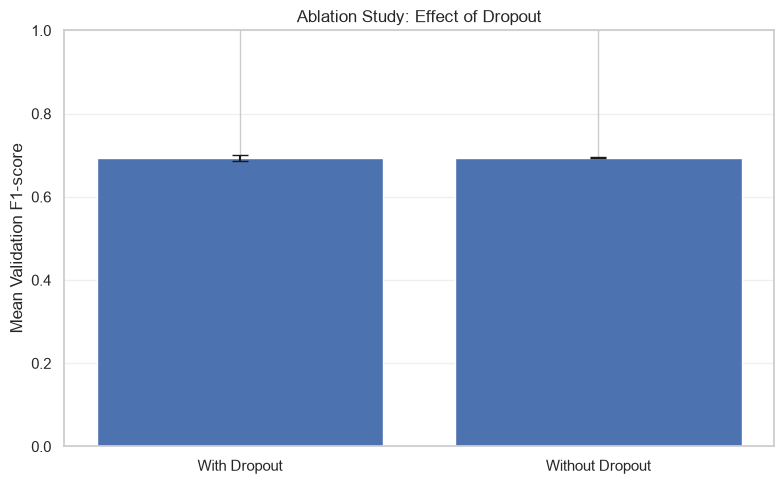


Ablation study results saved successfully!


In [76]:

original = pd.read_csv(
    METRICS_DIR / "three_seed_results.csv"
)

original = original[
    original["Model"] == "Deep MLP"
].copy()

original["Configuration"] = "With Dropout"
original["Dropout"] = 0.30

no_dropout = pd.read_csv(
    METRICS_DIR / "ablation_no_dropout_results.csv"
)

columns = [
    "Seed", "Configuration", "Dropout",
    "Epochs", "Accuracy", "Precision",
    "Recall", "F1-score", "ROC-AUC"
]

comparison = pd.concat(
    [original[columns], no_dropout[columns]],
    ignore_index=True
)

comparison = comparison.sort_values(
    ["Seed", "Dropout"], ascending=[True, False]
)

print("===== ABLATION INDIVIDUAL RESULTS =====")
print(comparison.round(4).to_string(index=False))

summary = comparison.groupby("Configuration")[
    ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
].agg(["mean", "std"])

print("\n===== ABLATION MEAN AND STD =====")
print(summary.round(4))

comparison.to_csv(
    METRICS_DIR / "ablation_comparison.csv",
    index=False
)

summary.to_csv(
    METRICS_DIR / "ablation_mean_std.csv"
)

# Graph: mean F1 and variability
fig, ax = plt.subplots(figsize=(8, 5))

f1_stats = comparison.groupby("Configuration")[
    "F1-score"
].agg(["mean", "std"])

ax.bar(
    f1_stats.index,
    f1_stats["mean"],
    yerr=f1_stats["std"],
    capsize=6
)

ax.set_title("Ablation Study: Effect of Dropout")
ax.set_ylabel("Mean Validation F1-score")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "ablation_dropout_comparison.png",
    dpi=300
)
plt.show()

print("\nAblation study results saved successfully!")


# T4.3 : Error Analysis of Deep MLP Predictions

===== T4.3 ERROR ANALYSIS =====
Total validation samples: 6513
Correct predictions: 5625
Incorrect predictions: 888

Error type counts:
Error_Type
False Negative    542
False Positive    346
Name: count, dtype: int64

Five incorrect predictions:
 Validation_Index  Actual_Label  Predicted_Label  Probability_Above_50K  Correct     Error_Type
                7             0                1               0.732551    False False Positive
               31             0                1               0.669241    False False Positive
               57             0                1               0.701364    False False Positive
                3             1                0               0.481605    False False Negative
               13             1                0               0.088816    False False Negative

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.93      0.91      4945
           1       0.75      0.65      0.70  

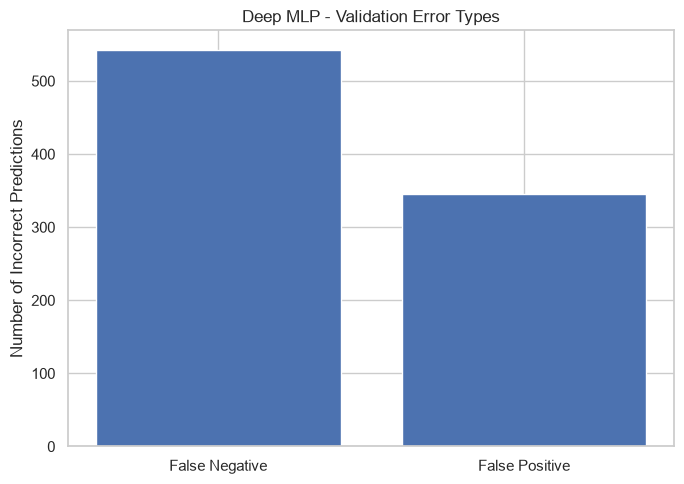


T4.3 error analysis saved successfully!


In [77]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report

METRICS_DIR = Path("outputs/metrics")
FIGURES_DIR = Path("outputs/figures")
METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load best Deep MLP from the repeated-seed experiment
model_path = Path("outputs/models/deep_mlp_seed_42.keras")

assert model_path.exists(), f"Missing checkpoint: {model_path}"

error_model = tf.keras.models.load_model(model_path)

X_error = np.asarray(X_val_tf, dtype=np.float32)
y_error = np.asarray(y_val_tf).ravel().astype(int)

# Predict probabilities and classes
probabilities = error_model.predict(
    X_error, verbose=0
).ravel()

predictions = (probabilities >= 0.5).astype(int)

# Create validation prediction table
error_df = pd.DataFrame({
    "Validation_Index": np.arange(len(y_error)),
    "Actual_Label": y_error,
    "Predicted_Label": predictions,
    "Probability_Above_50K": probabilities,
    "Correct": y_error == predictions
})

error_df["Error_Type"] = np.select(
    [
        (y_error == 0) & (predictions == 1),
        (y_error == 1) & (predictions == 0)
    ],
    [
        "False Positive",
        "False Negative"
    ],
    default="Correct"
)

incorrect = error_df[~error_df["Correct"]].copy()

print("===== T4.3 ERROR ANALYSIS =====")
print("Total validation samples:", len(error_df))
print("Correct predictions:", error_df["Correct"].sum())
print("Incorrect predictions:", len(incorrect))

print("\nError type counts:")
print(incorrect["Error_Type"].value_counts())

print("\nFive incorrect predictions:")
examples = pd.concat([
    incorrect[incorrect["Error_Type"] == "False Positive"].head(3),
    incorrect[incorrect["Error_Type"] == "False Negative"].head(2)
])
print(examples.to_string(index=False))

print("\nClassification Report:")
print(classification_report(y_error, predictions))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_error, predictions)
print(cm)

# Save results
error_df.to_csv(
    METRICS_DIR / "deep_mlp_validation_predictions.csv",
    index=False
)

incorrect.to_csv(
    METRICS_DIR / "deep_mlp_error_analysis.csv",
    index=False
)

examples.to_csv(
    METRICS_DIR / "five_incorrect_predictions.csv",
    index=False
)

# Plot error types
counts = incorrect["Error_Type"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(counts.index, counts.values)
plt.title("Deep MLP - Validation Error Types")
plt.ylabel("Number of Incorrect Predictions")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "deep_mlp_error_types.png",
    dpi=300
)
plt.show()

print("\nT4.3 error analysis saved successfully!")


# T4.4 : Robustness Analysis Across Age Groups

In [78]:

import pandas as pd
import numpy as np

print("---- AVAILABLE DATA VARIABLES ----")

names = [
    "X_train", "X_val", "X_valid",
    "X_train_raw", "X_val_raw",
    "X_train_df", "X_val_df",
    "df", "adult_df", "train_df",
    "train_indices", "val_indices",
    "X_train_tf", "X_val_tf"
]

for name in names:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}")
        print("Type:", type(obj).__name__)
        print("Shape:", getattr(obj, "shape", "N/A"))

        if isinstance(obj, pd.DataFrame):
            print("Columns:", list(obj.columns[:15]))
            if "age" in obj.columns:
                print("Age preview:", obj["age"].head().tolist())

print("\n===== SAVED SPLIT FILE =====")
from pathlib import Path

split_file = Path("outputs/splits/split_indices.npz")

if split_file.exists():
    with np.load(split_file) as splits:
        for key in splits.files:
            print(key, splits[key].shape)
else:
    print("Split file not found at expected path.")


---- AVAILABLE DATA VARIABLES ----

X_train
Type: DataFrame
Shape: (26048, 14)
Columns: ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country']
Age preview: [32, 43, 20, 40, 24]

X_val
Type: DataFrame
Shape: (6513, 14)
Columns: ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country']
Age preview: [31, 20, 78, 32, 61]

train_df
Type: DataFrame
Shape: (32561, 15)
Columns: ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']
Age preview: [39, 50, 38, 53, 28]

X_train_tf
Type: ndarray
Shape: (26048, 105)

X_val_tf
Type: ndarray
Shape: (6513, 105)

===== SAVED SPLIT FILE =====
t

# T4.4 : Robustness Analysis Across Age Groups
`Objective: Determine whether your Deep MLP performs consistently across different age groups, rather than relying only on overall accuracy.`

===== T4.4 AGE-GROUP ROBUSTNESS RESULTS =====
Age_Group  Samples  Positive_Samples  Accuracy  Precision  Recall  F1-score  ROC-AUC
    17-29     1938                98    0.9623     0.7660  0.3673    0.4966   0.9450
    30-44     2495               740    0.8244     0.7260  0.6554    0.6889   0.8940
    45-59     1564               595    0.8075     0.7653  0.7126    0.7380   0.8872
      60+      516               135    0.8527     0.7864  0.6000    0.6807   0.8776


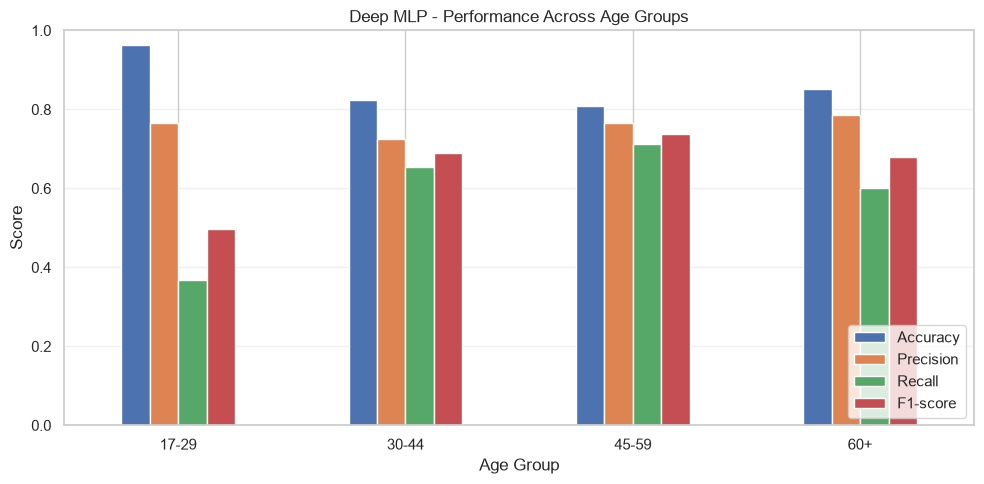


Total evaluated samples: 6513
Highest F1 age group: 45-59
Lowest F1 age group: 17-29

T4.4 robustness analysis completed!


In [79]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

METRICS_DIR = Path("outputs/metrics")
FIGURES_DIR = Path("outputs/figures")

METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# 1. Load existing best Deep MLP checkpoint
model = tf.keras.models.load_model(
    "outputs/models/deep_mlp_seed_42.keras"
)

# 2. Original validation ages
ages = pd.to_numeric(
    X_val["age"], errors="coerce"
).to_numpy()

X_robust = np.asarray(X_val_tf, dtype=np.float32)
y_robust = np.asarray(y_val_tf).ravel().astype(int)

# 3. Verify alignment and age data
assert len(ages) == len(X_robust) == len(y_robust)
assert np.isfinite(ages).all()
assert np.all((ages >= 17) & (ages <= 120))

# Confirm original validation row order against saved indices
with np.load("outputs/splits/split_indices.npz") as splits:
    val_indices = splits["val_idx"]

assert np.array_equal(
    X_val.index.to_numpy(),
    train_df.iloc[val_indices].index.to_numpy()
), "Validation row order does not match saved split!"

# 4. Generate predictions
probabilities = model.predict(
    X_robust, verbose=0
).ravel()

predictions = (probabilities >= 0.5).astype(int)

# 5. Define age groups
age_groups = pd.cut(
    ages,
    bins=[16, 29, 44, 59, np.inf],
    labels=["17-29", "30-44", "45-59", "60+"]
)

# 6. Calculate metrics for each group
results = []

for group in age_groups.categories:
    mask = np.asarray(age_groups == group)

    actual = y_robust[mask]
    predicted = predictions[mask]
    probs = probabilities[mask]

    if len(actual) == 0:
        continue

    result = {
        "Age_Group": str(group),
        "Samples": len(actual),
        "Positive_Samples": int(actual.sum()),
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1-score": f1_score(
            actual, predicted, zero_division=0
        ),
        "ROC-AUC": (
            roc_auc_score(actual, probs)
            if len(np.unique(actual)) == 2
            else np.nan
        )
    }

    results.append(result)

robustness_df = pd.DataFrame(results)

print("===== T4.4 AGE-GROUP ROBUSTNESS RESULTS =====")
print(robustness_df.round(4).to_string(index=False))

# 7. Save metrics
robustness_df.to_csv(
    METRICS_DIR / "age_group_robustness.csv",
    index=False
)

# 8. Plot performance
plot_df = robustness_df.set_index("Age_Group")

ax = plot_df[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Deep MLP - Performance Across Age Groups")
ax.set_xlabel("Age Group")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "age_group_robustness.png",
    dpi=300
)
plt.show()

# 9. Summary
print("\nTotal evaluated samples:",
      robustness_df["Samples"].sum())

print("Highest F1 age group:",
      robustness_df.loc[
          robustness_df["F1-score"].idxmax(),
          "Age_Group"
      ])

print("Lowest F1 age group:",
      robustness_df.loc[
          robustness_df["F1-score"].idxmin(),
          "Age_Group"
      ])

print("\nT4.4 robustness analysis completed!")


# T4.5 : Final Held-Out Test Evaluation

In [80]:

from pathlib import Path
import numpy as np
import pandas as pd

print("===== TEST DATA VARIABLES =====")

names = [
    "X_test", "y_test", "test_df",
    "X_test_tf", "y_test_tf",
    "preprocessor", "preprocessing_pipeline",
    "logistic_model", "lr_model",
    "deep_mlp", "rbf_model"
]

for name in names:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}")
        print("Type:", type(obj).__name__)
        print("Shape:", getattr(obj, "shape", "N/A"))

        if isinstance(obj, pd.DataFrame):
            print("Columns:", list(obj.columns))

print("\n===== SAVED MODELS =====")
for p in sorted(Path("outputs/models").glob("*")):
    print(p.name)

print("\n===== SAVED PREPROCESSORS =====")
for p in sorted(Path("outputs").rglob("*")):
    if p.is_file() and (
        "preprocess" in p.name.lower()
        or "pipeline" in p.name.lower()
    ):
        print(p)

print("\n===== DATA FILES =====")
for p in sorted(Path("data").glob("*")):
    if p.is_file():
        print(p.name)


===== TEST DATA VARIABLES =====

X_test
Type: DataFrame
Shape: (16281, 14)
Columns: ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country']

y_test
Type: Series
Shape: (16281,)

test_df
Type: DataFrame
Shape: (16281, 15)
Columns: ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']

preprocessor
Type: ColumnTransformer
Shape: N/A

logistic_model
Type: LogisticRegression
Shape: N/A

deep_mlp
Type: Sequential
Shape: N/A

rbf_model
Type: Sequential
Shape: N/A

===== SAVED MODELS =====
deep_mlp_best.keras
deep_mlp_seed_123.keras
deep_mlp_seed_2026.keras
deep_mlp_seed_42.keras
mlp_no_dropout_seed_123.keras
mlp_no_dropout_seed_2026.keras
mlp_no_dropout_seed_42.keras
numpy_mlp_best.npz
numpy_mlp_training_history.

In [81]:
import numpy as np
import pandas as pd
import joblib
import tensorflow as tf
from pathlib import Path

MODEL_DIR = Path("outputs/models")
METRICS_DIR = Path("outputs/metrics")
FIGURE_DIR = Path("outputs/figures")

METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Load the training-fitted preprocessor
saved_preprocessor = joblib.load(
    MODEL_DIR / "preprocessor.joblib"
)

# Transform ONLY - never fit on test data
X_test_processed = saved_preprocessor.transform(X_test)

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

X_test_processed = np.asarray(
    X_test_processed, dtype=np.float32
)

# Encode the official Adult Income test labels
if pd.api.types.is_numeric_dtype(y_test):
    y_test_final = np.asarray(y_test).ravel().astype(int)
else:
    labels = (
        pd.Series(y_test)
        .astype(str)
        .str.strip()
        .str.rstrip(".")
    )
    assert set(labels.unique()).issubset(
        {"<=50K", ">50K"}
    ), f"Unexpected test labels: {labels.unique()}"

    y_test_final = (
        labels == ">50K"
    ).astype(int).to_numpy()

assert X_test_processed.shape == (16281, 105)
assert len(y_test_final) == len(X_test_processed)
assert set(np.unique(y_test_final)) == {0, 1}
assert np.isfinite(X_test_processed).all()

print("===== FINAL TEST DATA =====")
print("Test features:", X_test_processed.shape)
print("Test labels:", y_test_final.shape)
print("Class counts:", np.bincount(y_test_final))
print("Preprocessing completed without refitting!")


===== FINAL TEST DATA =====
Test features: (16281, 105)
Test labels: (16281,)
Class counts: [12435  3846]
Preprocessing completed without refitting!


In [82]:

from sklearn.linear_model import LogisticRegression

# Use existing fitted baseline model
final_logistic = logistic_model

# Load Deep MLP checkpoint
final_deep_mlp = tf.keras.models.load_model(
    MODEL_DIR / "deep_mlp_seed_42.keras"
)

# Load RBF checkpoint with custom layer
final_rbf = tf.keras.models.load_model(
    MODEL_DIR / "rbf_network_seed_42.keras",
    custom_objects={
        "GaussianRBFLayer": GaussianRBFLayer
    }
)

assert hasattr(final_logistic, "classes_"), (
    "Logistic Regression is not fitted."
)

assert final_deep_mlp.input_shape[-1] == X_test_processed.shape[1]
assert final_rbf.input_shape[-1] == X_test_processed.shape[1]

print("All three models loaded successfully!")
print("Logistic classes:", final_logistic.classes_)
print("Deep MLP parameters:", final_deep_mlp.count_params())
print("RBF parameters:", final_rbf.count_params())


All three models loaded successfully!
Logistic classes: [0 1]
Deep MLP parameters: 8897
RBF parameters: 3394


In [83]:

import time
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

results = []
test_predictions = {}

models = {
    "Logistic Regression": final_logistic,
    "Deep MLP": final_deep_mlp,
    "RBF Network": final_rbf
}

for name, model in models.items():
    print(f"\n===== {name} =====")

    # Warm-up to reduce first-call overhead
    if name == "Logistic Regression":
        model.predict_proba(X_test_processed[:32])
    else:
        model.predict(
            X_test_processed[:32], verbose=0
        )

    start = time.perf_counter()

    if name == "Logistic Regression":
        positive_idx = list(model.classes_).index(1)
        probs = model.predict_proba(
            X_test_processed
        )[:, positive_idx]
    else:
        probs = model.predict(
            X_test_processed, verbose=0
        ).ravel()

    inference_seconds = time.perf_counter() - start

    preds = (probs >= 0.5).astype(int)

    cm = confusion_matrix(
        y_test_final, preds, labels=[0, 1]
    )
    tn, fp, fn, tp = cm.ravel()

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test_final, preds),
        "Precision": precision_score(
            y_test_final, preds, zero_division=0
        ),
        "Recall": recall_score(
            y_test_final, preds, zero_division=0
        ),
        "F1-score": f1_score(
            y_test_final, preds, zero_division=0
        ),
        "Specificity": tn / (tn + fp),
        "ROC-AUC": roc_auc_score(
            y_test_final, probs
        ),
        "Average Precision": average_precision_score(
            y_test_final, probs
        ),
        "Inference_Seconds": inference_seconds,
        "Milliseconds_Per_Sample": (
            inference_seconds / len(preds) * 1000
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }

    results.append(metrics)
    test_predictions[name] = {
        "probabilities": probs,
        "predictions": preds,
        "confusion_matrix": cm
    }

    print(classification_report(
        y_test_final, preds, digits=4
    ))
    print("Confusion matrix:")
    print(cm)
    print(f"Inference: {inference_seconds:.3f} seconds")

final_test_df = pd.DataFrame(results)

final_test_df.to_csv(
    METRICS_DIR / "final_heldout_test_results.csv",
    index=False
)

print("\n===== FINAL HELD-OUT TEST COMPARISON =====")
print(final_test_df.round(4).to_string(index=False))
print("\nFinal test results saved successfully!")



===== Logistic Regression =====
              precision    recall  f1-score   support

           0     0.8806    0.9315    0.9053     12435
           1     0.7275    0.5915    0.6525      3846

    accuracy                         0.8512     16281
   macro avg     0.8041    0.7615    0.7789     16281
weighted avg     0.8444    0.8512    0.8456     16281

Confusion matrix:
[[11583   852]
 [ 1571  2275]]
Inference: 0.012 seconds

===== Deep MLP =====
              precision    recall  f1-score   support

           0     0.8892    0.9267    0.9075     12435
           1     0.7255    0.6266    0.6724      3846

    accuracy                         0.8558     16281
   macro avg     0.8073    0.7766    0.7900     16281
weighted avg     0.8505    0.8558    0.8520     16281

Confusion matrix:
[[11523   912]
 [ 1436  2410]]
Inference: 0.475 seconds

===== RBF Network =====
              precision    recall  f1-score   support

           0     0.8796    0.9392    0.9084     12435
         

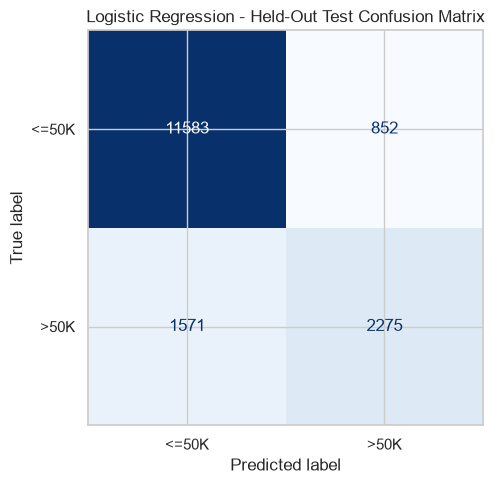

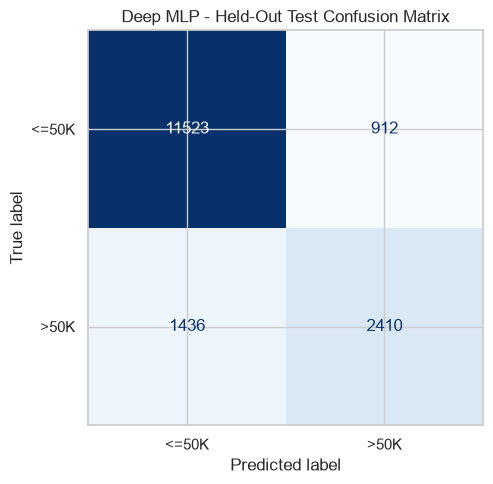

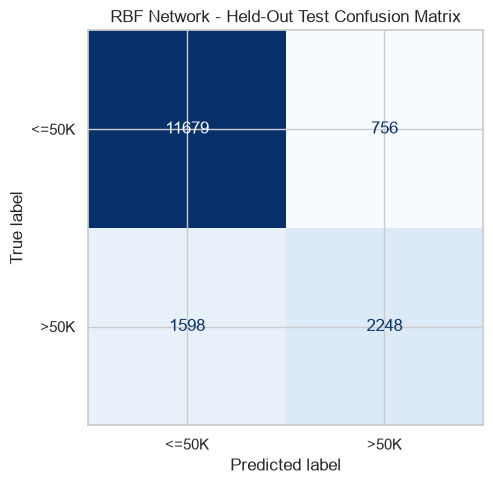

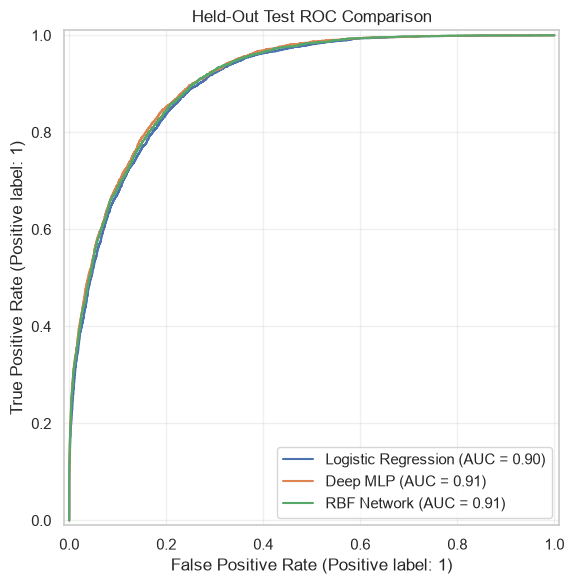

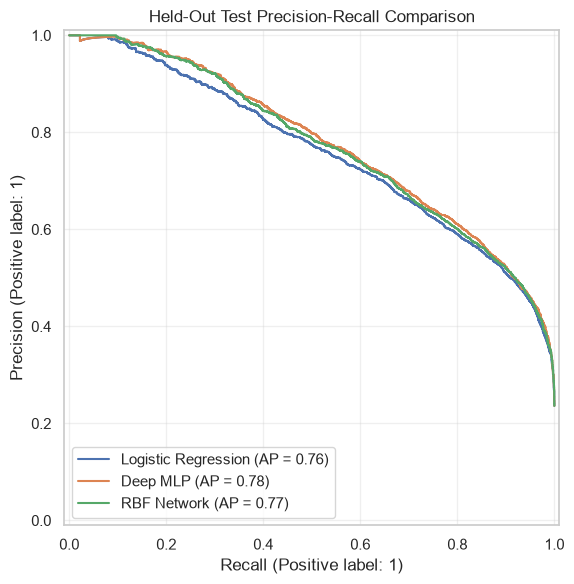

All final test figures saved successfully!


In [84]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Confusion matrices
for name, data in test_predictions.items():
    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay(
        confusion_matrix=data["confusion_matrix"],
        display_labels=["<=50K", ">50K"]
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(f"{name} - Held-Out Test Confusion Matrix")
    plt.tight_layout()

    filename = name.lower().replace(" ", "_")
    plt.savefig(
        FIGURE_DIR / f"{filename}_test_confusion_matrix.png",
        dpi=300
    )
    plt.show()

# ROC comparison
fig, ax = plt.subplots(figsize=(8, 6))

for name, data in test_predictions.items():
    RocCurveDisplay.from_predictions(
        y_test_final,
        data["probabilities"],
        name=name,
        ax=ax
    )

ax.set_title("Held-Out Test ROC Comparison")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "final_test_roc_comparison.png",
    dpi=300
)
plt.show()

# Precision-recall comparison
fig, ax = plt.subplots(figsize=(8, 6))

for name, data in test_predictions.items():
    PrecisionRecallDisplay.from_predictions(
        y_test_final,
        data["probabilities"],
        name=name,
        ax=ax
    )

ax.set_title("Held-Out Test Precision-Recall Comparison")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "final_test_pr_comparison.png",
    dpi=300
)
plt.show()

print("All final test figures saved successfully!")


# T5.1 : Final Model Recommendation

In [85]:

import pandas as pd
from pathlib import Path

METRICS_DIR = Path("outputs/metrics")

final_results = pd.read_csv(
    METRICS_DIR / "final_heldout_test_results.csv"
)

seed_results = pd.read_csv(
    METRICS_DIR / "three_seed_results.csv"
)

# Summarise validation stability
stability = (
    seed_results.groupby("Model")["F1-score"]
    .agg(["mean", "std"])
    .reset_index()
    .rename(columns={
        "mean": "Validation_F1_Mean",
        "std": "Validation_F1_Std"
    })
)

recommendation = final_results.merge(
    stability, on="Model", how="left"
)

# The recommended model was selected using validation
# evidence; the test results confirm its performance.
recommended_name = "Deep MLP"

assert recommended_name in recommendation["Model"].values

recommendation["Recommended"] = (
    recommendation["Model"] == recommended_name
)

recommendation.to_csv(
    METRICS_DIR / "final_model_recommendation.csv",
    index=False
)

print("===== FINAL MODEL RECOMMENDATION =====")
print(recommendation.round(4).to_string(index=False))

print("\nRecommended model:", recommended_name)
print("Reason: Strong validation F1, stable repeated")
print("runs, and competitive final test performance.")
print("\nT5.1 completed!")


===== FINAL MODEL RECOMMENDATION =====
              Model  Accuracy  Precision  Recall  F1-score  Specificity  ROC-AUC  Average Precision  Inference_Seconds  Milliseconds_Per_Sample    TN  FP   FN   TP  Validation_F1_Mean  Validation_F1_Std  Recommended
Logistic Regression    0.8512     0.7275  0.5915    0.6525       0.9315   0.9040             0.7590             0.0116                   0.0007 11583 852 1571 2275                 NaN                NaN        False
           Deep MLP    0.8558     0.7255  0.6266    0.6724       0.9267   0.9107             0.7775             0.4750                   0.0292 11523 912 1436 2410              0.6937             0.0065         True
        RBF Network    0.8554     0.7483  0.5845    0.6564       0.9392   0.9084             0.7727             0.3905                   0.0240 11679 756 1598 2248              0.6804             0.0048        False

Recommended model: Deep MLP
Reason: Strong validation F1, stable repeated
runs, and competitive 

# T5.2 : Saved-Model Inference Demonstration

In [86]:

import pandas as pd
import numpy as np
import joblib
import tensorflow as tf
from pathlib import Path

MODEL_DIR = Path("outputs/models")

inference_preprocessor = joblib.load(
    MODEL_DIR / "preprocessor.joblib"
)

inference_model = tf.keras.models.load_model(
    MODEL_DIR / "deep_mlp_seed_42.keras"
)

def predict_income(record):
    # Validate required features
    expected = list(inference_preprocessor.feature_names_in_)

    missing = set(expected) - set(record)
    extra = set(record) - set(expected)

    if missing or extra:
        raise ValueError(
            f"Missing features: {missing}; Extra features: {extra}"
        )

    age = float(record["age"])
    hours = float(record["hours_per_week"])

    if not 17 <= age <= 120:
        raise ValueError("Age must be between 17 and 120.")

    if not 1 <= hours <= 99:
        raise ValueError("Hours per week must be 1–99.")

    input_df = pd.DataFrame([record])[expected]

    processed = inference_preprocessor.transform(input_df)

    if hasattr(processed, "toarray"):
        processed = processed.toarray()

    processed = np.asarray(processed, dtype=np.float32)

    probability = float(
        inference_model.predict(processed, verbose=0)[0, 0]
    )

    prediction = ">50K" if probability >= 0.5 else "<=50K"

    return {
        "Predicted_Income": prediction,
        "Probability_Above_50K": round(probability, 4)
    }


# Demonstrate on an existing validation record.
# It is unseen during training, but was used in validation.
sample = X_val.iloc[0].to_dict()

print("===== SAVED-MODEL INFERENCE =====")
print("Input record:", sample)
print("Prediction:", predict_income(sample))

# Demonstrate invalid input handling
invalid_sample = sample.copy()
invalid_sample["age"] = -5

try:
    predict_income(invalid_sample)
except ValueError as error:
    print("\nInvalid input correctly rejected:", error)

print("\nT5.2 inference demonstration completed!")


===== SAVED-MODEL INFERENCE =====
Input record: {'age': 31, 'workclass': 'Self-emp-inc', 'fnlwgt': 117963, 'education': 'Doctorate', 'education_num': 16, 'marital_status': 'Never-married', 'occupation': 'Prof-specialty', 'relationship': 'Own-child', 'race': 'White', 'sex': 'Male', 'capital_gain': 0, 'capital_loss': 0, 'hours_per_week': 40, 'native_country': 'United-States'}
Prediction: {'Predicted_Income': '<=50K', 'Probability_Above_50K': 0.1278}

Invalid input correctly rejected: Age must be between 17 and 120.

T5.2 inference demonstration completed!


In [98]:

# ANN CW1 - LIVE DEMONSTRATION
# Run T5.2 first to load the saved model and preprocessor.


# STEP 1: Manual sample input
sample_input = {
    "age": 35,
    "workclass": "Private",
    "fnlwgt": 200000,
    "education": "Bachelors",
    "education_num": 13,
    "marital_status": "Never-married",
    "occupation": "Prof-specialty",
    "relationship": "Not-in-family",
    "race": "White",
    "sex": "Male",
    "capital_gain": 0,
    "capital_loss": 0,
    "hours_per_week": 40,
    "native_country": "United-States"
}



# STEP 2: Display input
print("\n1. INPUT DATA")
print(pd.DataFrame([sample_input]).to_string(index=False))

# STEP 3: Preprocessing
input_df = pd.DataFrame([sample_input])
expected = list(inference_preprocessor.feature_names_in_)
input_df = input_df[expected]

processed = inference_preprocessor.transform(input_df)

print("\n2. PREPROCESSING")
print("Original features:", input_df.shape[1])
print("Processed features:", processed.shape[1])

# STEP 4: Model configuration
print("\n3. MODEL CONFIGURATION")
print("Model: Deep MLP")
print("Input size:", inference_model.input_shape[-1])
print("Classification threshold: 0.5")

# STEP 5: Live prediction
result = predict_income(sample_input)
probability = result["Probability_Above_50K"]

print("\n4. PREDICTION")
print("Probability of >50K:", probability)
print("Predicted income:", result["Predicted_Income"])

# STEP 6: Explain the decision
print("\n5. DECISION EXPLANATION")
if probability >= 0.5:
    print("Probability >= 0.5, so prediction is >50K")
else:
    print("Probability < 0.5, so prediction is <=50K")





1. INPUT DATA
 age workclass  fnlwgt education  education_num marital_status     occupation  relationship  race  sex  capital_gain  capital_loss  hours_per_week native_country
  35   Private  200000 Bachelors             13  Never-married Prof-specialty Not-in-family White Male             0             0              40  United-States

2. PREPROCESSING
Original features: 14
Processed features: 105

3. MODEL CONFIGURATION
Model: Deep MLP
Input size: 105
Classification threshold: 0.5

4. PREDICTION
Probability of >50K: 0.158
Predicted income: <=50K

5. DECISION EXPLANATION
Probability < 0.5, so prediction is <=50K



# T5.3 : Limitations 

## Limitations

1. **Class Imbalance:** The Adult Income dataset contains more <=50K records than >50K records. The Deep MLP achieved 85.58% test accuracy, but its positive-class recall was only 62.66%.

2. **False Negatives:** The model incorrectly classified 1,436 higher-income test records as <=50K, indicating difficulty detecting some positive cases.

3. **Subgroup Performance:** Validation performance differed across age groups. The 17–29 group achieved 96.23% accuracy but only 36.73% positive-class recall. This demonstrates why accuracy alone is insufficient.

4. **Dataset Limitations:** The Adult Income dataset is historical and may not represent current employment patterns, salaries or populations.

5. **Limited Repeated Experiments:** Three random seeds were used. More repetitions and external datasets would provide stronger evidence of generalisation.

6. **Inference Efficiency:** Logistic Regression was faster in the measured inference run, while Deep MLP achieved better predictive performance. Timing results depend on the hardware and execution environment.

## Final Conclusion

  The Deep MLP was selected as the recommended architecture aschieved the highest mean validation F1 scor score of framework neural networks and performeperformed very well held-out test set. The RBF networknetwork was a worthwhile alternative architecture andssion provided a veryprovided a verybaseline. The experiments clearly show clearly showselection should be based on be based onn, recall, stability, computational efficiency and subgroup performance rather than accuracy alone.




# T6.1 : Automatic Reproducibility and Submission Verification

In [88]:

from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path.cwd()
OUT = ROOT / "outputs"

required_files = {
    "Dataset - Training": ROOT / "data/adult.data",
    "Dataset - Test": ROOT / "data/adult.test",
    "Dataset - Description": ROOT / "data/adult.names",
    "Saved Preprocessor": OUT / "models/preprocessor.joblib",
    "NumPy MLP": OUT / "models/numpy_mlp_best.npz",
    "Deep MLP": OUT / "models/deep_mlp_seed_42.keras",
    "RBF Network": OUT / "models/rbf_network_seed_42.keras",
    "Saved Split Indices": OUT / "splits/split_indices.npz",
    "Three-Seed Results": OUT / "metrics/three_seed_results.csv",
    "Three-Seed Summary": OUT / "metrics/three_seed_mean_std.csv",
    "Ablation Results": OUT / "metrics/ablation_comparison.csv",
    "Error Analysis": OUT / "metrics/deep_mlp_error_analysis.csv",
    "Age-Group Robustness": OUT / "metrics/age_group_robustness.csv",
    "Final Test Results": OUT / "metrics/final_heldout_test_results.csv",
    "Model Recommendation": OUT / "metrics/final_model_recommendation.csv",
    "README": ROOT / "README.md",
    "Requirements": ROOT / "requirements.txt",
    "Requirements Lock": ROOT / "requirements-lock.txt"
}

file_checks = []

for description, path in required_files.items():
    exists = path.is_file()
    size = path.stat().st_size if exists else 0

    file_checks.append({
        "Item": description,
        "Status": "PASS" if exists and size > 0 else "FAIL",
        "Size_KB": round(size / 1024, 2),
        "Path": str(path.relative_to(ROOT))
    })

file_report = pd.DataFrame(file_checks)

print("===== T6.1 REQUIRED FILE VERIFICATION =====")
print(file_report.to_string(index=False))

print("\nPassed:",
      (file_report["Status"] == "PASS").sum())
print("Failed:",
      (file_report["Status"] == "FAIL").sum())

assert (file_report["Status"] == "PASS").all(), (
    "Some required files are missing or empty."
)

print("\nAll required files verified!")


===== T6.1 REQUIRED FILE VERIFICATION =====
                 Item Status  Size_KB                                           Path
   Dataset - Training   PASS  3881.16                                data\adult.data
       Dataset - Test   PASS  1956.20                                data\adult.test
Dataset - Description   PASS     5.11                               data\adult.names
   Saved Preprocessor   PASS     6.42             outputs\models\preprocessor.joblib
            NumPy MLP   PASS    15.34              outputs\models\numpy_mlp_best.npz
             Deep MLP   PASS   131.89          outputs\models\deep_mlp_seed_42.keras
          RBF Network   PASS   115.85       outputs\models\rbf_network_seed_42.keras
  Saved Split Indices   PASS   254.89               outputs\splits\split_indices.npz
   Three-Seed Results   PASS     1.02         outputs\metrics\three_seed_results.csv
   Three-Seed Summary   PASS     0.56        outputs\metrics\three_seed_mean_std.csv
     Ablation Results

In [89]:

import joblib
import tensorflow as tf

from sklearn.linear_model import LogisticRegression

print("===== SAVED MODEL VERIFICATION =====")

# Load preprocessing
check_preprocessor = joblib.load(
    OUT / "models/preprocessor.joblib"
)

assert hasattr(check_preprocessor, "transform")
assert hasattr(check_preprocessor, "feature_names_in_")

print("PASS: Preprocessor loaded")

# Load Deep MLP
check_mlp = tf.keras.models.load_model(
    OUT / "models/deep_mlp_seed_42.keras"
)

print("PASS: Deep MLP loaded")
print("Deep MLP parameters:", check_mlp.count_params())

# Load RBF
check_rbf = tf.keras.models.load_model(
    OUT / "models/rbf_network_seed_42.keras",
    custom_objects={
        "GaussianRBFLayer": GaussianRBFLayer
    }
)

print("PASS: RBF loaded")
print("RBF parameters:", check_rbf.count_params())

# Verify NumPy MLP parameters
with np.load(
    OUT / "models/numpy_mlp_best.npz",
    allow_pickle=False
) as numpy_model:
    print("PASS: NumPy MLP archive readable")
    print("Stored arrays:", numpy_model.files)

# Check feature dimensions
assert check_mlp.input_shape[-1] == 105
assert check_rbf.input_shape[-1] == 105

print("\nAll saved models verified successfully!")


===== SAVED MODEL VERIFICATION =====
PASS: Preprocessor loaded
PASS: Deep MLP loaded
Deep MLP parameters: 8897
PASS: RBF loaded
RBF parameters: 3394
PASS: NumPy MLP archive readable
Stored arrays: ['W1', 'b1', 'W2', 'b2', 'best_epoch', 'learning_rate', 'batch_size', 'seed']

All saved models verified successfully!


In [90]:

print("===== EXPERIMENT REPRODUCIBILITY CHECK =====")

seed_df = pd.read_csv(
    OUT / "metrics/three_seed_results.csv"
)

ablation_df = pd.read_csv(
    OUT / "metrics/ablation_comparison.csv"
)

test_df_check = pd.read_csv(
    OUT / "metrics/final_heldout_test_results.csv"
)

# Six runs: 2 architectures × 3 seeds
expected_seeds = {42, 123, 2026}

for model_name in ["Deep MLP", "RBF Network"]:
    subset = seed_df[seed_df["Model"] == model_name]

    assert len(subset) == 3
    assert set(subset["Seed"]) == expected_seeds

print("PASS: Six repeated neural model experiments")

# Ablation: 3 seeds with dropout + 3 without
assert len(ablation_df) == 6

for configuration in ["With Dropout", "Without Dropout"]:
    subset = ablation_df[
        ablation_df["Configuration"] == configuration
    ]
    assert set(subset["Seed"]) == expected_seeds

print("PASS: Six ablation experiment records")

# Final test: baseline + two neural architectures
assert set(test_df_check["Model"]) == {
    "Logistic Regression", "Deep MLP", "RBF Network"
}

print("PASS: Three final test models evaluated")

# Validate metric ranges
metric_columns = [
    "Accuracy", "Precision", "Recall",
    "F1-score", "ROC-AUC"
]

for frame in [seed_df, ablation_df, test_df_check]:
    assert frame[metric_columns].notna().all().all()
    assert frame[metric_columns].apply(
        lambda column: column.between(0, 1).all()
    ).all()

print("PASS: All classification metrics within [0, 1]")

print("\nExperiment verification completed!")


===== EXPERIMENT REPRODUCIBILITY CHECK =====
PASS: Six repeated neural model experiments
PASS: Six ablation experiment records
PASS: Three final test models evaluated
PASS: All classification metrics within [0, 1]

Experiment verification completed!


In [91]:

print("===== INFERENCE SMOKE TEST =====")

# Use an existing validation record
sample_record = X_val.iloc[0].to_dict()

valid_result = predict_income(sample_record)

assert valid_result["Predicted_Income"] in [
    "<=50K", ">50K"
]

assert 0 <= valid_result["Probability_Above_50K"] <= 1

print("PASS: Valid record prediction")
print("Prediction:", valid_result)

# Test invalid age
invalid_record = sample_record.copy()
invalid_record["age"] = -5

try:
    predict_income(invalid_record)
except ValueError:
    print("PASS: Invalid age rejected")
else:
    raise AssertionError(
        "Invalid age was incorrectly accepted."
    )

print("\nInference smoke test passed!")


===== INFERENCE SMOKE TEST =====
PASS: Valid record prediction
Prediction: {'Predicted_Income': '<=50K', 'Probability_Above_50K': 0.1278}
PASS: Invalid age rejected

Inference smoke test passed!


In [92]:

from datetime import datetime
import platform
import sklearn
import tensorflow as tf
import numpy as np
import pandas as pd

verification = {
    "Verification_Date": datetime.now().isoformat(),
    "Python_Version": platform.python_version(),
    "TensorFlow_Version": tf.__version__,
    "Scikit_Learn_Version": sklearn.__version__,
    "NumPy_Version": np.__version__,
    "Pandas_Version": pd.__version__,
    "Required_Files": len(file_report),
    "Files_Passed": int(
        (file_report["Status"] == "PASS").sum()
    ),
    "Files_Failed": int(
        (file_report["Status"] == "FAIL").sum()
    ),
    "Repeated_Experiments": len(seed_df),
    "Ablation_Experiments": len(ablation_df),
    "Final_Test_Models": len(test_df_check),
    "Recommended_Model": "Deep MLP",
    "Verification_Status": "PASS"
}

report = pd.DataFrame([verification])

report_path = OUT / "metrics/reproducibility_verification.csv"

report.to_csv(report_path, index=False)

print("===== FINAL REPRODUCIBILITY REPORT =====")
print(report.T.to_string(header=False))

print("\nReport saved:", report_path)
print("\nT6.1 verification completed successfully!")


===== FINAL REPRODUCIBILITY REPORT =====
Verification_Date     2026-11-09T14:08:53.643523
Python_Version                            3.13.5
TensorFlow_Version                        2.21.0
Scikit_Learn_Version                       1.9.1
NumPy_Version                              2.5.4
Pandas_Version                             2.3.3
Required_Files                                18
Files_Passed                                  18
Files_Failed                                   0
Repeated_Experiments                           6
Ablation_Experiments                           6
Final_Test_Models                              3
Recommended_Model                       Deep MLP
Verification_Status                         PASS

Report saved: c:\Users\MSii\Desktop\ANN CW\outputs\metrics\reproducibility_verification.csv

T6.1 verification completed successfully!


# T6.2 : Final Submission Package 

In [95]:

from pathlib import Path
import json
import pandas as pd

ROOT = Path.cwd()

print("---- FINAL SUBMISSION CHECK ----")

# Find Jupyter notebooks
notebooks = list(ROOT.glob("*.ipynb"))

print("\nNotebooks:")
for notebook in notebooks:
    print(" -", notebook.name)

assert notebooks, "No Jupyter notebook found!"

# Validate notebook JSON
for notebook in notebooks:
    with open(notebook, encoding="utf-8") as f:
        data = json.load(f)

    assert "cells" in data
    assert "metadata" in data

    print(
        f"PASS: {notebook.name} "
        f"({len(data['cells'])} cells)"
    )

# Check essential documentation
documents = [
    "README.md",
    "requirements.txt",
    "requirements-lock.txt"
]

for filename in documents:
    path = ROOT / filename
    assert path.is_file() and path.stat().st_size > 0
    print("PASS:", filename)

# Check final outputs
required_outputs = [
    "outputs/metrics/final_heldout_test_results.csv",
    "outputs/metrics/final_model_recommendation.csv",
    "outputs/metrics/reproducibility_verification.csv",
    "outputs/models/deep_mlp_seed_42.keras",
    "outputs/models/rbf_network_seed_42.keras",
    "outputs/models/preprocessor.joblib"
]

for filename in required_outputs:
    path = ROOT / filename
    assert path.is_file() and path.stat().st_size > 0
    print("PASS:", filename)

# Check figure count
figures = list((ROOT / "outputs/figures").glob("*.png"))

print("\nSaved figures:", len(figures))

# Check notebook size
for notebook in notebooks:
    size_mb = notebook.stat().st_size / (1024 ** 2)
    print(f"{notebook.name}: {size_mb:.2f} MB")

print("\nT6.2 submission package verification completed!")


---- FINAL SUBMISSION CHECK ----

Notebooks:
 - ANN_Adult_Income.ipynb
PASS: ANN_Adult_Income.ipynb (79 cells)
PASS: README.md
PASS: requirements.txt
PASS: requirements-lock.txt
PASS: outputs/metrics/final_heldout_test_results.csv
PASS: outputs/metrics/final_model_recommendation.csv
PASS: outputs/metrics/reproducibility_verification.csv
PASS: outputs/models/deep_mlp_seed_42.keras
PASS: outputs/models/rbf_network_seed_42.keras
PASS: outputs/models/preprocessor.joblib

Saved figures: 15
ANN_Adult_Income.ipynb: 0.68 MB

T6.2 submission package verification completed!


In [ ]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED


# T6.3 - FINAL ANN CW1 SUBMISSION PACKAGE
# Student Index: KIC-BSCCSAI-251P-012


ROOT = Path.cwd()

ZIP_NAME = "ANN CW01(KIC-BSCCSAI-251P-012).zip"
ZIP_PATH = ROOT / ZIP_NAME

# STEP 1: Required files
include_files = [
    "ANN_Adult_Income.ipynb",
    "README.md",
    "requirements.txt",
    "requirements-lock.txt",
    "Demo Drive Link.txt"
]

# STEP 2: Required folders
include_folders = [
    "data",
    "outputs/models",
    "outputs/metrics",
    "outputs/figures",
    "outputs/splits"
]

# STEP 3: Exclusions
exclude_names = {
    ".DS_Store",
    "Thumbs.db"
}

exclude_folders = {
    ".venv",
    "venv",
    "__pycache__",
    ".ipynb_checkpoints",
    ".git"
}

files_to_zip = []

print("ANN CW1 - FINAL SUBMISSION PACKAGING")

# STEP 4: Check required files
print("\nSTEP 1: Checking required files...")

for filename in include_files:
    path = ROOT / filename

    if not path.is_file():
        raise FileNotFoundError(
            f"Required file missing: {filename}"
        )

    files_to_zip.append(path)
    print("FOUND:", filename)

# STEP 5: Find final PDF report
print("\nSTEP 2: Checking final report...")

report_files = sorted(
    ROOT.glob("CW1 Practical Technical Record*.pdf")
)

if not report_files:
    raise FileNotFoundError(
        "Final CW1 Practical Technical Record PDF is missing."
    )

if len(report_files) > 1:
    raise ValueError(
        "Multiple matching reports found. "
        "Keep only the final PDF or specify its filename."
    )

report_path = report_files[0]
files_to_zip.append(report_path)

print("FOUND:", report_path.name)

# STEP 6: Collect dataset and output files
print("\nSTEP 3: Collecting dataset and output files...")

for folder in include_folders:

    folder_path = ROOT / folder

    if not folder_path.is_dir():
        raise FileNotFoundError(
            f"Required folder missing: {folder}"
        )

    folder_files = 0

    for path in folder_path.rglob("*"):

        if not path.is_file():
            continue

        if path.name in exclude_names:
            continue

        if any(
            part in exclude_folders
            for part in path.relative_to(ROOT).parts
        ):
            continue

        files_to_zip.append(path)
        folder_files += 1

    print(f"FOUND: {folder} ({folder_files} files)")

# STEP 7: Remove duplicates
files_to_zip = sorted(set(files_to_zip))

# STEP 8: Create final ZIP
print("\nSTEP 4: Creating ZIP archive...")

with ZipFile(ZIP_PATH, "w", ZIP_DEFLATED) as zip_file:

    for path in files_to_zip:

        relative_path = path.relative_to(ROOT).as_posix()

        zip_file.write(
            path,
            arcname=relative_path
        )

print("ZIP created successfully!")

# STEP 9: Verify archive
print("\nSTEP 5: Verifying ZIP integrity...")

with ZipFile(ZIP_PATH, "r") as zip_file:

    bad_file = zip_file.testzip()

    if bad_file is not None:
        raise RuntimeError(
            f"Corrupt file found: {bad_file}"
        )

    archive_names = set(zip_file.namelist())

    for path in files_to_zip:

        relative_path = path.relative_to(ROOT).as_posix()

        if relative_path not in archive_names:
            raise RuntimeError(
                f"Missing from ZIP: {relative_path}"
            )

    # Ensure demonstration link is included
    assert "Demo Drive Link.txt" in archive_names

    # Ensure final report is included
    assert report_path.name in archive_names

# STEP 10: Final summary
print("\n" + "=" * 60)
print("FINAL ANN CW1 SUBMISSION PACKAGE")
print("=" * 60)

print("ZIP Name:", ZIP_NAME)
print("ZIP Location:", ZIP_PATH)
print("Total Files:", len(files_to_zip))

print(
    "ZIP Size:",
    round(
        ZIP_PATH.stat().st_size / (1024 ** 2),
        2
    ),
    "MB"
)

print("\nPASS: ZIP integrity verified")
print("PASS: Jupyter Notebook included")
print("PASS: Final PDF report included")
print("PASS: Demo Drive Link.txt included")
print("PASS: Dataset included")
print("PASS: Trained models included")
print("PASS: Evaluation metrics included")
print("PASS: Figures and splits included")
print("PASS: README and requirements included")

print("\nT6.3 COMPLETED SUCCESSFULLY!")
